<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>

<h2>Unidade Curricular: Aprendizado de Máquina</h2>
<h2>Trabalho análise exploratória de dados (EDA)</h2>

<h2>Alunos:</h2>

<ul>
  <li>Adair Limana</li>
  <li>Jones Bussmann</li>
  <li>Miriam Stal</li>
  <li>Nathan Hoepers</li>
  <li>Vera Azevedo</li>
</ul>

# **Contexto de Negócio**

Somos consultores de dados contratados pelo departamento de crédito consignado com garantia de imóvel (home equity) de uma instituição financeira. A área de concessão de crédito quer automatizar parte da decisão de aprovação de empréstimos, seguindo as recomendações do Equal Credit Opportunity Act — ou seja, precisa de um modelo estatisticamente sólido e explicável, não uma “caixa-preta”.

Antes de qualquer modelagem (que faremos em aulas futuras), a diretoria de risco pediu uma análise exploratória completa:
1. Entender quem são os tomadores de empréstimo;
2. Onde estão os problemas de qualidade dos dados;
3. Quais variáveis parecem mais associadas à inadimplência.


**Perguntas de negócio:**

1. Quais características dos tomadores de empréstimo estão associadas a um maior risco de inadimplência;
2. A base de dados está em condições de sustentar essa análise com confiança?

**Base de dados**

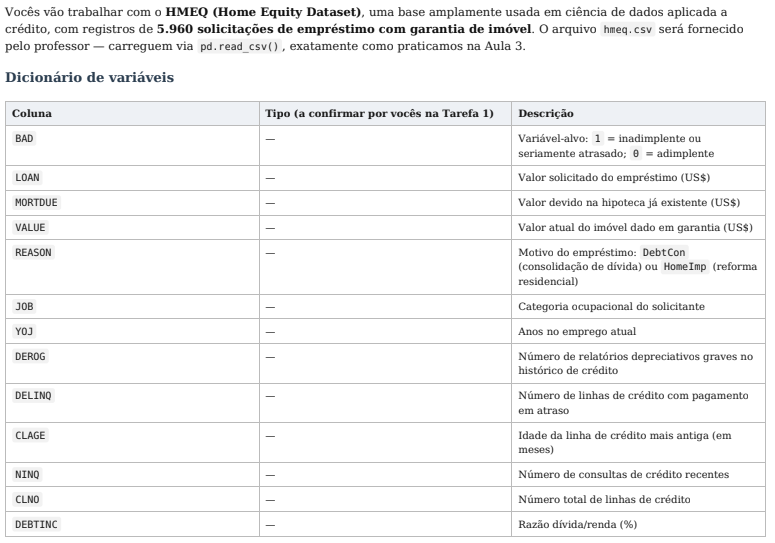

# Imports e dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


In [ ]:
# Arquivo de dados compartilhado com acesso a qualquer pessoa com link
file_id = "1UIad_ImBiggbCpFPQhCIXURiS9NjAZPH"
url = f"https://drive.google.com/uc?id={file_id}"
df_original = pd.read_csv(url)

df = df_original.copy()

# Funções auxiliares

In [ ]:
def renomear_colunas_hmeq(df, avisar_ausentes=True):
    """
    Renomeia as colunas do dataset HMEQ do inglês para português,
    seguindo o dicionário de/para padrão.
    """
    de_para = {
        'BAD': 'target_inadimplencia',
        'LOAN': 'valor_emprestimo',
        'MORTDUE': 'valor_divida_hipoteca',
        'VALUE': 'valor_imovel',
        'REASON': 'motivo_emprestimo',
        'JOB': 'categoria_ocupacional',
        'YOJ': 'anos_emprego_atual',
        'DEROG': 'qtd_registros_credito_negativos',
        'DELINQ': 'qtd_linhas_credito_atrasadas',
        'CLAGE': 'idade_linha_credito_mais_antiga_meses',
        'NINQ': 'qtd_consultas_credito_recentes',
        'CLNO': 'qtd_linhas_credito',
        'DEBTINC': 'percentual_divida_renda'
    }

    if avisar_ausentes:
        ausentes = set(de_para.keys()) - set(df.columns)
        if ausentes:
            print(f"Aviso: colunas não encontradas no DataFrame: {ausentes}")

    return df.rename(columns=de_para)


def imputar_percentual_divida_renda(df_entrada, n_neighbors=5):
    """
    Imputa valores ausentes em 'percentual_divida_renda' usando KNNImputer,
    considerando as demais colunas numéricas e categóricas do dataset HMEQ.
    """

    df_saida = df_entrada.copy()  # não altera o df original passado como argumento

    # 1. Definir colunas a usar (exclui target e qtd_nulos_linha)
    colunas_numericas = [
        "valor_emprestimo",
        "valor_divida_hipoteca",
        "valor_imovel",
        "anos_emprego_atual",
        "qtd_registros_credito_negativos",
        "qtd_linhas_credito_atrasadas",
        "idade_linha_credito_mais_antiga_meses",
        "qtd_consultas_credito_recentes",
        "qtd_linhas_credito",
        "percentual_divida_renda"
    ]

    colunas_categoricas = [
        "motivo_emprestimo",
        "categoria_ocupacional"
    ]

    # 2. Transformar categóricas em dummies
    df_dummies = pd.get_dummies(df_saida[colunas_categoricas], drop_first=True)

    # 3. Juntar numéricas + dummies
    df_para_imputar = pd.concat([df_saida[colunas_numericas], df_dummies], axis=1)

    # 4. Escalar os dados
    scaler = StandardScaler()
    df_scaled = pd.DataFrame(
        scaler.fit_transform(df_para_imputar),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 5. Rodar o KNNImputer
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df_imputado_scaled = pd.DataFrame(
        imputer.fit_transform(df_scaled),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 6. Reverter a escala
    df_imputado = pd.DataFrame(
        scaler.inverse_transform(df_imputado_scaled),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 7. Substituir apenas a coluna de interesse
    df_saida["percentual_divida_renda"] = df_imputado["percentual_divida_renda"]

    return df_saida


def taxa_faltante_por_grupo(df, coluna_grupo, coluna_alvo):
    taxa = df.groupby(coluna_grupo)[coluna_alvo].apply(
        lambda col: col.isnull().mean()
    ).round(4)
    return taxa


def skew_kurt(df, coluna):
    """
    Calcula e imprime skewness e kurtosis (excesso, fisher=True) de uma coluna numérica.
    """
    skew_val = stats.skew(df[coluna])
    kurt_val = stats.kurtosis(df[coluna])  # excesso de curtose (fisher=True, padrão)

    print(f"Skewness de {coluna}: {skew_val:.2f}")
    print(f"Kurtosis (excesso) de {coluna}: {kurt_val:.2f}")


def plot_dist_boxplot(df, coluna, bins=30, cor="steelblue"):
    """
    Plota histograma + KDE e boxplot de uma coluna numérica lado a lado.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Histograma + KDE
    sns.histplot(df[coluna], bins=bins, kde=True, ax=axes[0], color=cor)
    axes[0].set_title(f"Distribuição de {coluna} (histograma + KDE)")
    axes[0].set_xlabel(coluna)

    # Boxplot
    sns.boxplot(x=df[coluna], ax=axes[1], color=cor)
    axes[1].set_title(f"Boxplot de {coluna}")
    axes[1].set_xlabel(coluna)

    plt.tight_layout()
    plt.show()


def outliers_iqr(df, coluna):
    """
    Calcula limites de outliers pela regra do IQR (1.5x) para uma coluna numérica
    e retorna o subconjunto do DataFrame com os outliers.
    """
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"Q1 = {Q1:.1f} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}")
    print(f"Limite inferior = {limite_inferior:.1f} | Limite superior = {limite_superior:.1f}")
    print(f"Quantidade de outliers pela regra do IQR: {len(outliers)}\n")

    return outliers


def outliers_zscore(df, coluna, limite=3):
    """
    Identifica outliers pelo critério do Z-Score (|Z| > limite) de uma coluna numérica.
    """
    z_scores = stats.zscore(df[coluna], nan_policy="omit")

    outliers = df[np.abs(z_scores) > limite]

    print(f"Quantidade de outliers pelo critério de Z-Score (|Z| > {limite}): {len(outliers)}")

    return outliers

# **Bloco 1 - Inspeção Estrutural**

**Tarefa 1:** Completem o dicionário de variáveis acima, classificando cada coluna em Qualitativa Nominal / Qualitativa Ordinal / Quantitativa Discreta / Quantitativa Contínua, com uma frase de justificativa para cada uma.

**Criado um DE x PARA para melhor entendimento das variáveis**

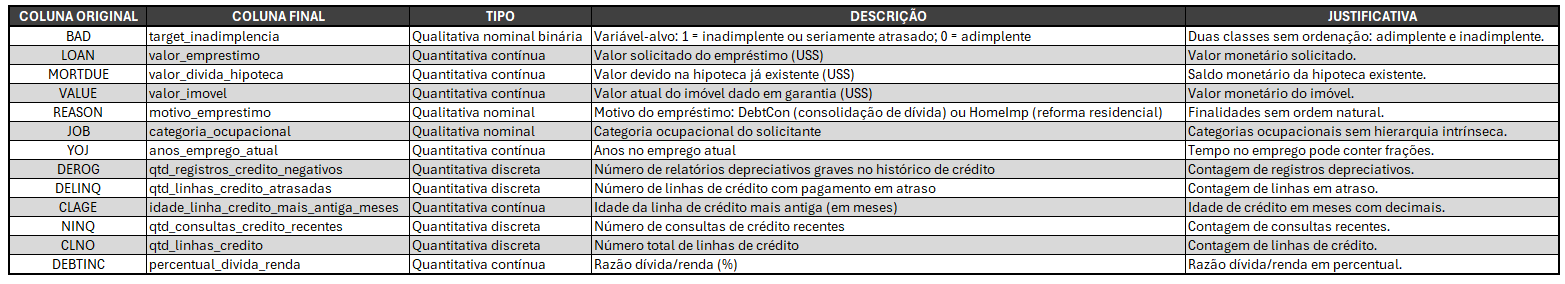

**Tarefa 2:** Façam a auditoria de formato ( shape , dtypes , info() , head() , tail() ) e verifiquem a coerência dos nomes de
colunas (padronizem se necessário).

In [ ]:
print(f'Colunas do DF carregado: {df.columns}\n')
print(f'Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

Colunas do DF carregado: Index(['BAD', 'LOAN', 'MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG',
       'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC'],
      dtype='object')

Possui: 5960 linhas, 13 colunas.


In [ ]:
#Renomear colunas do DF para melhor entendimento das variáveis
df = renomear_colunas_hmeq(df)

print(f'Colunas renomeadas do DF: {df.columns}\n')

Colunas renomeadas do DF: Index(['target_inadimplencia', 'valor_emprestimo', 'valor_divida_hipoteca',
       'valor_imovel', 'motivo_emprestimo', 'categoria_ocupacional',
       'anos_emprego_atual', 'qtd_registros_credito_negativos',
       'qtd_linhas_credito_atrasadas', 'idade_linha_credito_mais_antiga_meses',
       'qtd_consultas_credito_recentes', 'qtd_linhas_credito',
       'percentual_divida_renda'],
      dtype='object')



In [ ]:
df.dtypes

,0
target_inadimplencia,int64
valor_emprestimo,int64
valor_divida_hipoteca,float64
valor_imovel,float64
motivo_emprestimo,object
categoria_ocupacional,object
anos_emprego_atual,float64
qtd_registros_credito_negativos,float64
qtd_linhas_credito_atrasadas,float64
idade_linha_credito_mais_antiga_meses,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5960 non-null   int64  
 1   valor_emprestimo                       5960 non-null   int64  
 2   valor_divida_hipoteca                  5442 non-null   float64
 3   valor_imovel                           5848 non-null   float64
 4   motivo_emprestimo                      5708 non-null   object 
 5   categoria_ocupacional                  5681 non-null   object 
 6   anos_emprego_atual                     5445 non-null   float64
 7   qtd_registros_credito_negativos        5252 non-null   float64
 8   qtd_linhas_credito_atrasadas           5380 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5652 non-null   float64
 10  qtd_consultas_credito_recentes         5450 non-null   float64
 11  qtd_

In [ ]:
df.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [ ]:
df.tail()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda
5955,0,88900,57264.0,90185.0,DebtCon,Other,16.0,0.0,0.0,221.808718,0.0,16.0,36.112347
5956,0,89000,54576.0,92937.0,DebtCon,Other,16.0,0.0,0.0,208.692070,0.0,15.0,35.859971
5957,0,89200,54045.0,92924.0,DebtCon,Other,15.0,0.0,0.0,212.279697,0.0,15.0,35.556590
5958,0,89800,50370.0,91861.0,DebtCon,Other,14.0,0.0,0.0,213.892709,0.0,16.0,34.340882
5959,0,89900,48811.0,88934.0,DebtCon,Other,15.0,0.0,0.0,219.601002,0.0,16.0,34.571519


Em comparação com a tabela do dicionário, seguem as colunas que terão o tipo de dado ajustado:
  1. valor_emprestimo: Alterar para "float";
  2. qtd_registros_credito_negativos: Alterar para "int";
  3. qtd_linhas_credito_atrasadas: Alterar para "int";
  4. qtd_consultas_credito_recentes: Alterar para "int";
  5. qtd_linhas_credito: Alterar para "int";

In [ ]:
# Alterando o tipo da variável "valor_emprestimo"
df['valor_emprestimo'] = df['valor_emprestimo'].astype('float64')

As colunas que devem virar INT poderemos fazer somente quando não houver valores nulos. Enquanto há valores nulos nas colunas, acontece o erro **"ValueError: Cannot convert non-finite values (NA or inf) to integer"**.

Portanto essa alteração será feita quando todos os valores ausentes não existirem mais no dataset.


In [ ]:
# Confirmando se a alteração surtiu efeito
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5960 non-null   int64  
 1   valor_emprestimo                       5960 non-null   float64
 2   valor_divida_hipoteca                  5442 non-null   float64
 3   valor_imovel                           5848 non-null   float64
 4   motivo_emprestimo                      5708 non-null   object 
 5   categoria_ocupacional                  5681 non-null   object 
 6   anos_emprego_atual                     5445 non-null   float64
 7   qtd_registros_credito_negativos        5252 non-null   float64
 8   qtd_linhas_credito_atrasadas           5380 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5652 non-null   float64
 10  qtd_consultas_credito_recentes         5450 non-null   float64
 11  qtd_

A base original possui 5.960 registros e 13 colunas. Foram inspecionados o formato, os tipos de armazenamento, os valores ausentes e os primeiros e últimos registros.

Os nomes das colunas foram traduzidos para facilitar a interpretação, mantendo um dicionário de correspondência com os nomes originais. As variáveis de contagem foram convertidas para int64 após a imputação, pois esse tipo não aceita valores ausentes. A conversão dos valores de empréstimo para float64 foi uma escolha de padronização.


**Tarefa 3:** "BAD" (o alvo - "target_inadimplencia") está balanceado ou desbalanceado? Calculem a proporção com .value_counts(normalize=True) e
expliquem por que isso importa para a análise que vem a seguir.

In [ ]:
df['target_inadimplencia'].value_counts(normalize=True)

,proportion
target_inadimplencia,
0,0.800503
1,0.199497


A variável BAD apresenta desbalanceamento: 4.771 registros são de adimplentes, correspondendo a 80,05%, e 1.189 são de inadimplentes ou seriamente atrasados, correspondendo a 19,95%.

Essa diferença exige atenção às proporções dentro de cada grupo durante a EDA. Em uma futura modelagem, prever todos os casos como adimplentes produziria aproximadamente 80% de acurácia, mas não identificaria nenhum inadimplente. Por isso, a avaliação deverá considerar também a capacidade de detectar a classe inadimplente.


**Por que isso importa?**

A classe **"BAD" (o alvo - "target_inadimplencia") = 1** (inadimplente) representa cerca de **20%** da base, contra ~80% de adimplentes — ou seja, a
base é **desbalanceada** (proporção aproximada 4:1). Isso é relevante para toda a análise que segue por três
motivos principais:

1. **Estatísticas descritivas e visualizações agregadas** (médias, medianas, boxplots) podem esconder o
   comportamento da classe minoritária, já que ela pesa pouco no total — é importante sempre segmentar por BAD e
   não só olhar para a base como um todo.
2. **Métricas de correlação e testes de associação** (Tarefas 11–13) precisam ser interpretados com cautela: uma
   associação fraca em termos absolutos ainda pode ser economicamente relevante para identificar o grupo de risco.
3. **Implicações para modelagem futura** (fora do escopo deste desafio, mas relevante para a diretoria de risco):
   com uma classe desbalanceada, métricas de acurácia serão enganosas em um modelo preditivo futuro; será
   necessário considerar métricas e técnicas de
   balanceamento para a modelagem futura.

# **Bloco 2 - Qualidade dos dados**

**Tarefa 7:** Verifiquem se existem linhas duplicadas e tratem se houver.

obs: decidimos iniciar o bloco com essa tarefa uma vez que se excluirmos algumas linhas nesse ponto, podemos eliminar possíveis erros que encontraríamos nas demais análises.

In [ ]:
df = df.drop_duplicates()
print(f'Após retirar as linhas duplicados o DF Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

#No DF não havia valores linhas duplicadas.

Após retirar as linhas duplicados o DF Possui: 5960 linhas, 13 colunas.


**Tarefa 4:** Gerem o mapa de calor de faltantes ( sns.heatmap(df.isnull()) ) e a contagem/percentual de faltantes por coluna.
Identifiquem as 3 colunas mais afetadas.

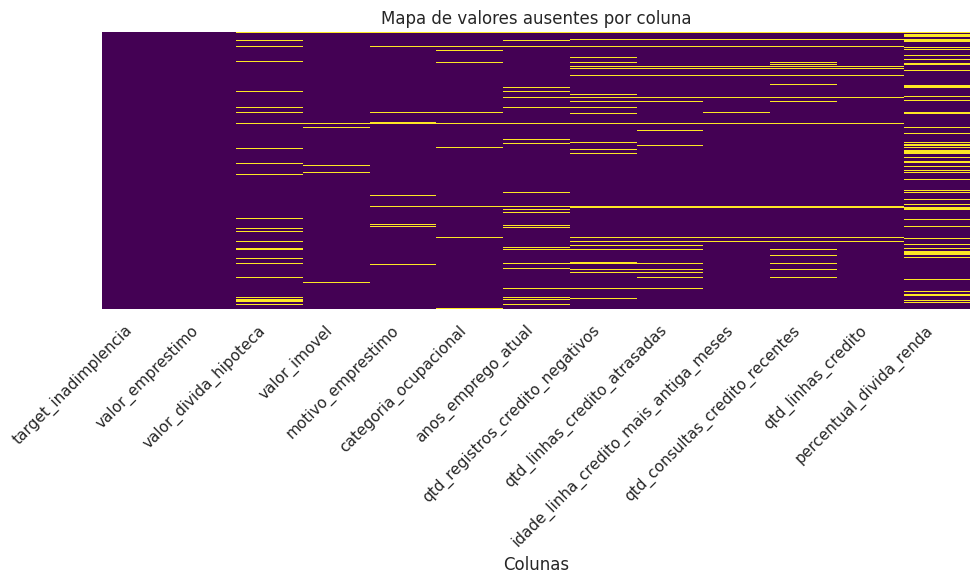

In [ ]:
# Mapa de calor
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de valores ausentes por coluna")
plt.xlabel("Colunas")

# Rotaciona os rótulos do eixo X na diagonal
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()



## Interpretação: Mapa de Valores Ausentes

A visualização revela dados ausentes entre as colunas do dataset:

- **Sem valores ausentes**: `target_inadimplencia` e `valor_emprestimo` aparecem completamente preenchidas (nenhuma linha amarela), o que é positivo — especialmente por `target_inadimplencia` ser a variável alvo do modelo.

- **Poucos valores ausentes**: `valor_divida_hipoteca`, `valor_imovel` e `motivo_emprestimo` apresentam ausências pontuais e esparsas, concentradas em poucos registros.

- **Ausências moderadas**: `categoria_ocupacional`, `anos_emprego_atual` e `qtd_linhas_credito_atrasadas` mostram um volume intermediário de dados faltantes, distribuídos ao longo do dataset.

- **Maior concentração de ausências**: `percentual_divida_renda` se destaca como a coluna com mais valores faltantes, com uma faixa densa de ausências visível na parte superior do gráfico — sugerindo que essa informação pode não ter sido coletada ou registrada para um subconjunto específico de clientes.

- **Padrão de blocos**: algumas colunas relacionadas a histórico de crédito (`qtd_registros_credito_negativos`, `qtd_consultas_credito_recentes`, `idade_linha_credito_mais_antiga_meses`) apresentam ausências que parecem coincidir nas mesmas linhas.


In [ ]:
# Contagem objetiva de faltantes por coluna
print("Valores faltantes por coluna:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1).sort_values(ascending=False))

Valores faltantes por coluna:
percentual_divida_renda                  1267
qtd_registros_credito_negativos           708
qtd_linhas_credito_atrasadas              580
valor_divida_hipoteca                     518
anos_emprego_atual                        515
qtd_consultas_credito_recentes            510
idade_linha_credito_mais_antiga_meses     308
categoria_ocupacional                     279
motivo_emprestimo                         252
qtd_linhas_credito                        222
valor_imovel                              112
valor_emprestimo                            0
target_inadimplencia                        0
dtype: int64

Percentual de faltantes por coluna:
percentual_divida_renda                  21.3
qtd_registros_credito_negativos          11.9
qtd_linhas_credito_atrasadas              9.7
valor_divida_hipoteca                     8.7
anos_emprego_atual                        8.6
qtd_consultas_credito_recentes            8.6
idade_linha_credito_mais_antiga_meses     5.2


Além de verificar o % de linhas com valores nulos, decidimos avaliar o número de colunas nulas das linhas, criando a coluna **"qtd_nulos_linha"**

In [ ]:
df['qtd_nulos_linha'] = df.isnull().sum(axis=1)
df.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
0,1,1100.0,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN,1
1,1,1300.0,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN,1
2,1,1500.0,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN,1
3,1,1500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11
4,0,1700.0,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN,1


In [ ]:
df_mais_5_nulos = df[df['qtd_nulos_linha'] > 5]
print(f'Número de linhas com mais de 5 colunas nulas: {df_mais_5_nulos.shape[0]}\n')
df_mais_5_nulos.head()

Número de linhas com mais de 5 colunas nulas: 192



,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
3,1,1500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11
10,1,2000.0,22608.0,NaN,NaN,NaN,18.0,NaN,NaN,NaN,NaN,NaN,NaN,9
17,1,2200.0,23030.0,NaN,NaN,NaN,19.0,NaN,NaN,NaN,NaN,NaN,3.711312,8
51,0,3100.0,NaN,70400.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10
63,1,3600.0,61584.0,61800.0,HomeImp,ProfExe,10.0,NaN,NaN,NaN,NaN,NaN,NaN,6


Resumo:
* Queremos excluir as linhas com mais de 5 colunas com valores ausentes, pois representam no mínimo 45% (6/13) dos dados faltantes;
* Encontramos 192 linhas nessa situação, o que representa um pouco mais de 3% do dataset (192/5960);
* Vamos apenas avaliar se a proporção da coluna `target_inadimplencia` desse dataset que queremos excluir é parecida com a proporção do dataset original;

In [ ]:
df_mais_5_nulos['target_inadimplencia'].value_counts(normalize=True)

,proportion
target_inadimplencia,
0,0.739583
1,0.260417


Foram identificadas 192 linhas com mais de cinco campos ausentes, correspondendo a 3,22% da base. Cada uma possui pelo menos seis das 13 variáveis sem informação, ou seja, 46,15% dos campos.

Optamos pela exclusão porque essas observações exigiriam reconstruir uma parcela elevada de suas informações. Entretanto, entre as linhas excluídas, 26,04% são inadimplentes, percentual superior aos 19,95% da base original. Foram removidos 50 inadimplentes e 142 adimplentes.

A taxa global de inadimplência passou de 19,95% para 19,75%. Embora a mudança global seja pequena, isso não garante ausência de viés em outros perfis de clientes. A exclusão constitui uma limitação da análise.


In [ ]:
df = df[df['qtd_nulos_linha'] <= 5]
print(f'Depois da exclusão o DF ficou com: {df.shape[0]} linhas, {df.shape[1]} colunas.')
# 5768 linhas, 14 colunas

Depois da exclusão o DF ficou com: 5768 linhas, 14 colunas.


Em resposta a tarefa 4, segue resultado final das colunas com % de valores ausentes em ordem decrescente:

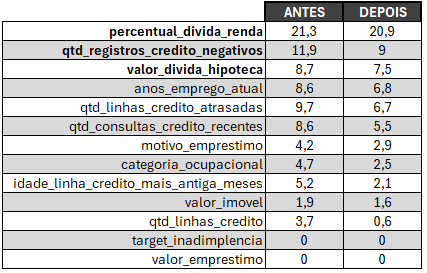

“ANTES” representa a base original de 5.960 registros. “DEPOIS” representa os 5.768 registros mantidos após a exclusão, **ainda antes da imputação**. Na base original, as três colunas mais afetadas são DEBTINC (1.267 ausentes; 21,26%), DEROG (708; 11,88%) e DELINQ (580; 9,73%).

Com o dataset completo, as colunas que tinham mais valores ausentes eram:
1. percentual_divida_renda
2. qtd_registros_credito_negativos
3. qtd_linhas_credito_atrasadas

Porém, com a exclusão das linhas com mais de 5 colunas com valores asentes a ordem ficou:
1. percentual_divida_renda
2. qtd_registros_credito_negativos
3. valor_divida_hipoteca

**Tarefa 6b:** (...) e das colunas categóricas ( REASON , JOB ) com uma estratégia justificada (moda, ou categoria explícita “Não informado”).

OBS: decidimos ajustar as colunas categóricas ("motivo_emprestimo" e "categoria_ocupacional") antes de investigar uma hipótese de mecanismo de ausência (MCAR, MAR ou MNAR) da coluna com mais valores ausentes ("percentual_divida_renda").

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5336 non-null   float64
 3   valor_imovel                           5675 non-null   float64
 4   motivo_emprestimo                      5602 non-null   object 
 5   categoria_ocupacional                  5622 non-null   object 
 6   anos_emprego_atual                     5374 non-null   float64
 7   qtd_registros_credito_negativos        5251 non-null   float64
 8   qtd_linhas_credito_atrasadas           5379 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5648 non-null   float64
 10  qtd_consultas_credito_recentes         5449 non-null   float64
 11  qtd_linha

In [ ]:
contagem = df['motivo_emprestimo'].value_counts(dropna=False)
percentual = df['motivo_emprestimo'].value_counts(dropna=False, normalize=True) * 100

resumo_motivo_emprestimo = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_motivo_emprestimo

,Contagem,Percentual (%)
motivo_emprestimo,,
DebtCon,3876,67.20
HomeImp,1726,29.92
NaN,166,2.88


In [ ]:
contagem = df['categoria_ocupacional'].value_counts(dropna=False)
percentual = df['categoria_ocupacional'].value_counts(dropna=False, normalize=True) * 100

resumo_categoria_ocupacional = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_categoria_ocupacional

,Contagem,Percentual (%)
categoria_ocupacional,,
Other,2360,40.92
ProfExe,1268,21.98
Office,942,16.33
Mgr,752,13.04
Self,191,3.31
NaN,146,2.53
Sales,109,1.89


### **Decisão sobre a imputação dos dados categóricos:**
* motivo_emprestimo: Vai pela moda, uma vez que seu volume é bem baixo em comparação com o dataset;
* categoria_ocupacional: por ser uma categoria genérica iremos incluir os valores ausentes na categoria "Other". Por acaso essa categoria também é a moda.

A imputação pela moda é uma estratégia permitida no enunciado. Preencher JOB (categoria ocupacional) com `Other` não significa que essa seja a ocupação real dos clientes sem informação. A opção simplifica o preenchimento, mas aumenta a frequência da categoria predominante. Uma alternativa para comparação futura é usar “Não informado”.

In [ ]:
moda_motivo_emprestimo = df['motivo_emprestimo'].mode()[0]
df['motivo_emprestimo'] = df['motivo_emprestimo'].fillna(moda_motivo_emprestimo)

valor_fixo_categoria_ocupacional = 'Other'
df['categoria_ocupacional'] = df['categoria_ocupacional'].fillna(valor_fixo_categoria_ocupacional)

print(f'Valores ausentes de "motivo_emprestimo" foram preenchidos com {moda_motivo_emprestimo}, já os de "categoria_ocupacional" com {valor_fixo_categoria_ocupacional}')

Valores ausentes de "motivo_emprestimo" foram preenchidos com DebtCon, já os de "categoria_ocupacional" com Other


In [ ]:
contagem = df['motivo_emprestimo'].value_counts(dropna=False)
percentual = df['motivo_emprestimo'].value_counts(dropna=False, normalize=True) * 100

resumo_motivo_emprestimo = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_motivo_emprestimo

,Contagem,Percentual (%)
motivo_emprestimo,,
DebtCon,4042,70.08
HomeImp,1726,29.92


In [ ]:
contagem = df['categoria_ocupacional'].value_counts(dropna=False)
percentual = df['categoria_ocupacional'].value_counts(dropna=False, normalize=True) * 100

resumo_categoria_ocupacional = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_categoria_ocupacional

,Contagem,Percentual (%)
categoria_ocupacional,,
Other,2506,43.45
ProfExe,1268,21.98
Office,942,16.33
Mgr,752,13.04
Self,191,3.31
Sales,109,1.89


**Tarefa 5:** Para a coluna com mais faltantes, investiguem uma hipótese de mecanismo de ausência (MCAR, MAR ou MNAR):
* A taxa de faltantes varia entre grupos de REASON ("motivo_emprestimo") ou JOB ("categoria_ocupacional") ?

Documentem a evidência a favor ou contra cada hipótese — não existe
resposta única “correta” aqui, o que importa é o raciocínio.

In [ ]:
print("Taxa de faltantes em 'percentual_divida_renda', por motivo de empréstimo:")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'percentual_divida_renda'))
# DebtCon (consolidação de dívida) e HomeImp (reforma/melhoria residencial)

Taxa de faltantes em 'percentual_divida_renda', por motivo de empréstimo:
motivo_emprestimo
DebtCon    0.2031
HomeImp    0.2219
Name: percentual_divida_renda, dtype: float64



As diferenças nas taxas de ausência entre as categorias ocupacionais enfraquecem a hipótese de MCAR e apresentam indícios compatíveis com MAR condicionado à categoria ocupacional. Entretanto, essa análise não permite descartar completamente um mecanismo MNAR.

In [ ]:
#Verificando as taxas faltantes por "categoria_ocupacional"
print("Taxa de faltantes em 'percentual_divida_renda', por categoria ocupacional:")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'percentual_divida_renda'))

Taxa de faltantes em 'percentual_divida_renda', por categoria ocupacional:
categoria_ocupacional
Mgr        0.2340
Office     0.1645
Other      0.2195
ProfExe    0.1924
Sales      0.2752
Self       0.2565
Name: percentual_divida_renda, dtype: float64


Há uma maior amplitude de **cerca 11 pontos percentuais** entre o menor e maior percentual, com indícios compatíveis com MAR em relação à variável "categoria_ocupacional".

* Mgr — Manager (gerente)
* Office — funções administrativas/escritório
* Other — outras categorias não especificadas
* ProfExe — Professional/Executive (profissional/executivo)
* Sales — vendas
* Self — Self-employed (autônomo)

Uma hipótese é que a renda variável em vendas ou trabalho autônomo dificulte informar "percentual_divida_renda". O dataset não permite confirmar essa explicação.

**MCAR, MAR e MNAR**

- **MCAR (ausência completamente ao acaso):** a chance de ausência não dependeria dos valores observados nem dos não observados. As diferenças por ocupação tornam essa hipótese menos plausível, mas a comparação descritiva não é uma prova definitiva.
- **MAR (ausência ao acaso condicionada às informações observadas):** a ausência poderia depender da ocupação ou de outras características conhecidas. Sob MAR, após considerar as informações observadas relevantes, a ausência não dependeria adicionalmente do próprio valor não observado de DEBTINC. A análise é compatível com essa hipótese, mas não a comprova.
- **MNAR (ausência não ao acaso):** o próprio comprometimento de renda não informado poderia influenciar a ausência, mesmo após considerar as características observadas. Por exemplo, clientes com comprometimento real mais elevado poderiam ter maior dificuldade ou resistência para informá-lo. Essa possibilidade não foi demonstrada nem descartada.

Adotamos MAR como hipótese de trabalho para a imputação, reconhecendo que não é possível distinguir conclusivamente MAR de MNAR somente com os dados observados.

Como os grupos REASON e JOB já foram preenchidos no cálculo anterior, a conferência abaixo recupera suas categorias originais, sem alterar o tratamento principal do grupo. Os índices das linhas foram preservados no notebook.

In [ ]:
# investigar a ausência nos grupos originais.
base_ausencias = renomear_colunas_hmeq(df_original).loc[df.index].copy()

for coluna_grupo in ["motivo_emprestimo", "categoria_ocupacional"]:
    resumo_ausencias = (
        base_ausencias
        .groupby(coluna_grupo, dropna=False)["percentual_divida_renda"]
        .agg(registros="size", ausentes=lambda s: s.isna().sum())
    )
    resumo_ausencias["percentual_ausentes"] = (
        resumo_ausencias["ausentes"] / resumo_ausencias["registros"] * 100
    )
    print(coluna_grupo)
    display(resumo_ausencias.round(2))

motivo_emprestimo


,registros,ausentes,percentual_ausentes
motivo_emprestimo,,,
DebtCon,3876,779,20.10
HomeImp,1726,383,22.19
NaN,166,42,25.30


categoria_ocupacional


,registros,ausentes,percentual_ausentes
categoria_ocupacional,,,
Mgr,752,176,23.40
Office,942,155,16.45
Other,2360,526,22.29
ProfExe,1268,244,19.24
Sales,109,30,27.52
Self,191,49,25.65
NaN,146,24,16.44


Com as categorias originais, a ausência de DEBTINC é de 20,10% em DebtCon e 22,19% em HomeImp. Entre as ocupações, é de 16,45% em Office, 27,52% em Sales e 25,65% em Self. A diferença Office/Sales é de 11,07 pontos percentuais. A pequena diferença em DebtCon em relação ao cálculo anterior (20,31%) decorre do preenchimento dos motivos ausentes pela moda naquele cálculo.

In [ ]:
# Guarda os valores originais não-nulos antes de imputar
mask_nao_nulo = df["percentual_divida_renda"].notnull()
valores_originais = df.loc[mask_nao_nulo, "percentual_divida_renda"].copy()

# Roda a imputação
df = imputar_percentual_divida_renda(df)

# Compara as colunas com valores não nulos com o DF final para verificar se o KNN mudou algum dados existente
diferenca = (df.loc[mask_nao_nulo, "percentual_divida_renda"] - valores_originais).abs()
print(diferenca.describe().round(4))

count    4564.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: percentual_divida_renda, dtype: float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5336 non-null   float64
 3   valor_imovel                           5675 non-null   float64
 4   motivo_emprestimo                      5768 non-null   object 
 5   categoria_ocupacional                  5768 non-null   object 
 6   anos_emprego_atual                     5374 non-null   float64
 7   qtd_registros_credito_negativos        5251 non-null   float64
 8   qtd_linhas_credito_atrasadas           5379 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5648 non-null   float64
 10  qtd_consultas_credito_recentes         5449 non-null   float64
 11  qtd_linha

**Dados da coluna "percentual_divida_renda" inseridos com sucesso com o método KNN. E avaliado que esse processo não alterou os dados que já existiam.**

**Tarefa 6a:** Tratem os faltantes das colunas numéricas (decidam e justifiquem: mediana, mediana por grupo, ou KNNImputer - como praticamos na Aula 3).

Ficou definido que:
* Valores abaixo de 7% será imputado pela mediana simples;
* Valores superiores a 7% vale a pena ter estudo, tal qual feito para a variável "percentual_divida_renda";

O patamar de 7% é uma escolha operacional para priorizar a investigação e não uma regra estatística universal.

Para DEBTINC, o KNN com cinco vizinhos aproveita a semelhança dos clientes em várias características. O código padroniza as variáveis e codifica as categorias, excluindo BAD e qtd_nulos_linha do cálculo. A escolha de cinco vizinhos é uma configuração do estudo e não foi demonstrada como a melhor possível. A mediana foi adotada nas demais imputações por sua resistência à influência de valores extremos; em MORTDUE, as diferenças de valor entre ocupações motivaram o uso da mediana por grupo.

As imputações permitem aproveitar mais registros, mas podem alterar distribuições e associações. Preservar os valores já informados não comprova a precisão das estimativas para os ausentes. As diferenças residuais na verificação dos valores observados, da ordem de 10⁻¹⁴, são compatíveis com arredondamento numérico ao padronizar e reverter a escala.

Em particular, preencher DEROG ou DELINQ com zero não comprova que o cliente não possuía registros negativos ou atrasos. Por isso, é importante recuperar ou guardar os indicadores de ausência original. Na futura modelagem, a padronização e a imputação deverão ser ajustadas somente nos dados de treinamento.

In [ ]:
print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))


Percentual de faltantes por coluna:
target_inadimplencia                     0.0
valor_emprestimo                         0.0
valor_divida_hipoteca                    7.5
valor_imovel                             1.6
motivo_emprestimo                        0.0
categoria_ocupacional                    0.0
anos_emprego_atual                       6.8
qtd_registros_credito_negativos          9.0
qtd_linhas_credito_atrasadas             6.7
idade_linha_credito_mais_antiga_meses    2.1
qtd_consultas_credito_recentes           5.5
qtd_linhas_credito                       0.6
percentual_divida_renda                  0.0
qtd_nulos_linha                          0.0
dtype: float64


In [ ]:
print("Taxa de faltantes em 'valor_divida_hipoteca' por 'motivo_emprestimo':")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'valor_divida_hipoteca'))

Taxa de faltantes em 'valor_divida_hipoteca' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    0.0505
HomeImp    0.1321
Name: valor_divida_hipoteca, dtype: float64


In [ ]:
print("Taxa de faltantes em 'valor_divida_hipoteca' por 'categoria_ocupacional':")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'valor_divida_hipoteca'))

Taxa de faltantes em 'valor_divida_hipoteca' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        0.0372
Office     0.0637
Other      0.1217
ProfExe    0.0126
Sales      0.0917
Self       0.0681
Name: valor_divida_hipoteca, dtype: float64


In [ ]:
# Mediana de valor_divida_hipoteca por categoria_ocupacional
mediana_por_categoria = df.groupby('categoria_ocupacional')['valor_divida_hipoteca'].median()
print("Mediana de 'valor_divida_hipoteca' por 'categoria_ocupacional':")
print(mediana_por_categoria)

print()

# Mediana de valor_divida_hipoteca por motivo_emprestimo
mediana_por_motivo = df.groupby('motivo_emprestimo')['valor_divida_hipoteca'].median()
print("Mediana de 'valor_divida_hipoteca' por 'motivo_emprestimo':")
print(mediana_por_motivo)

Mediana de 'valor_divida_hipoteca' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        76803.0
Office     62996.0
Other      54641.0
ProfExe    82921.0
Sales      71800.0
Self       87899.0
Name: valor_divida_hipoteca, dtype: float64

Mediana de 'valor_divida_hipoteca' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    66496.5
HomeImp    62833.0
Name: valor_divida_hipoteca, dtype: float64


Essa variação sugere que a ausência pode estar associada aos grupos observados, tornando MCAR uma hipótese menos plausível. Parece que quem não informa a hipoteca tende a se concentrar em certos perfis (ex: "Other" e "HomeImp"):

* Por motivo_emprestimo: HomeImp tem cerca de 2,6 vezes a taxa de faltantes (13,2%) comparado a DebtCon (5,1%)
* Por categoria_ocupacional: variação ainda maior — de 1,3% (ProfExe) a 12,2% (Other)

**Decisão final é usar mediana por grupo da variável 'categoria_ocupacional' para imputar dados em 'valor_divida_hipoteca', pois a categoria possui maior variabilidade da mediana em seus grupos.**

In [ ]:
print("Taxa de faltantes em 'qtd_registros_credito_negativos' por 'motivo_emprestimo':")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'qtd_registros_credito_negativos'))

Taxa de faltantes em 'qtd_registros_credito_negativos' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    0.1000
HomeImp    0.0655
Name: qtd_registros_credito_negativos, dtype: float64


In [ ]:
print("Taxa de faltantes em 'qtd_registros_credito_negativos' por 'categoria_ocupacional':")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'qtd_registros_credito_negativos'))

Taxa de faltantes em 'qtd_registros_credito_negativos' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        0.1250
Office     0.1093
Other      0.0918
ProfExe    0.0599
Sales      0.0917
Self       0.0209
Name: qtd_registros_credito_negativos, dtype: float64


In [ ]:
# Mediana de qtd_registros_credito_negativos por categoria_ocupacional
mediana_por_categoria = df.groupby('categoria_ocupacional')['qtd_registros_credito_negativos'].median()
print("Mediana de 'qtd_registros_credito_negativos' por categoria_ocupacional:")
print(mediana_por_categoria)

print()

# Mediana de qtd_registros_credito_negativos por motivo_emprestimo
mediana_por_motivo = df.groupby('motivo_emprestimo')['qtd_registros_credito_negativos'].median()
print("Mediana de 'qtd_registros_credito_negativos' por motivo_emprestimo:")
print(mediana_por_motivo)

Mediana de 'qtd_registros_credito_negativos' por categoria_ocupacional:
categoria_ocupacional
Mgr        0.0
Office     0.0
Other      0.0
ProfExe    0.0
Sales      0.0
Self       0.0
Name: qtd_registros_credito_negativos, dtype: float64

Mediana de 'qtd_registros_credito_negativos' por motivo_emprestimo:
motivo_emprestimo
DebtCon    0.0
HomeImp    0.0
Name: qtd_registros_credito_negativos, dtype: float64


**Há variação significativa nos grupos, porém, a mediana em todos os grupos é a mesma. Nesse sentido, podemos imputar com a mediana geral.**

In [ ]:
# Imputação com mediana
colunas_para_imputar = [
    "valor_imovel",
    "anos_emprego_atual",
    "qtd_linhas_credito_atrasadas",
    "idade_linha_credito_mais_antiga_meses",
    "qtd_consultas_credito_recentes",
    "qtd_linhas_credito",
    "qtd_registros_credito_negativos"
]

for col in colunas_para_imputar:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
# Imputação por mediana de grupo
# Mediana para dívida de hipoteca por categora ocupacional
mediana_valor_divida_hipoteca_por_categoria_ocupacional = df.groupby("categoria_ocupacional")["valor_divida_hipoteca"].transform("median")
df["valor_divida_hipoteca"] = df["valor_divida_hipoteca"].fillna(mediana_valor_divida_hipoteca_por_categoria_ocupacional)


In [ ]:
print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))


Percentual de faltantes por coluna:
target_inadimplencia                     0.0
valor_emprestimo                         0.0
valor_divida_hipoteca                    0.0
valor_imovel                             0.0
motivo_emprestimo                        0.0
categoria_ocupacional                    0.0
anos_emprego_atual                       0.0
qtd_registros_credito_negativos          0.0
qtd_linhas_credito_atrasadas             0.0
idade_linha_credito_mais_antiga_meses    0.0
qtd_consultas_credito_recentes           0.0
qtd_linhas_credito                       0.0
percentual_divida_renda                  0.0
qtd_nulos_linha                          0.0
dtype: float64


In [ ]:
# Depois de todos os dados imputados, podemos alterar o tipo da variável para inteiro
colunas_para_alterar_int = [
    "qtd_registros_credito_negativos",
    "qtd_linhas_credito_atrasadas",
    "qtd_consultas_credito_recentes",
    "qtd_linhas_credito"
]

for col in colunas_para_alterar_int:
    df[col] = df[col].astype('int64')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5768 non-null   float64
 3   valor_imovel                           5768 non-null   float64
 4   motivo_emprestimo                      5768 non-null   object 
 5   categoria_ocupacional                  5768 non-null   object 
 6   anos_emprego_atual                     5768 non-null   float64
 7   qtd_registros_credito_negativos        5768 non-null   int64  
 8   qtd_linhas_credito_atrasadas           5768 non-null   int64  
 9   idade_linha_credito_mais_antiga_meses  5768 non-null   float64
 10  qtd_consultas_credito_recentes         5768 non-null   int64  
 11  qtd_linha

# **Bloco 3 - Análise Univariada e Outliers**

**Tarefa 8:**
1. Calculem .describe()
2. Para as 3 variáveis contínuas que vocês julgarem mais relevantes para o negócio, calculem skewness e kurtosis, com histograma + KDE e boxplot.

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
target_inadimplencia,5768.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
valor_emprestimo,5768.0,18783.24,11286.37,1100.00,11200.00,16500.00,23500.00,89900.00
valor_divida_hipoteca,5768.0,72886.78,43206.05,2063.00,48002.25,63028.50,89025.25,399550.00
valor_imovel,5768.0,102078.62,57378.57,8000.00,66543.50,89720.00,119393.25,855909.00
anos_emprego_atual,5768.0,8.80,7.35,0.00,3.00,7.00,12.15,41.00
qtd_registros_credito_negativos,5768.0,0.23,0.81,0.00,0.00,0.00,0.00,10.00
qtd_linhas_credito_atrasadas,5768.0,0.42,1.09,0.00,0.00,0.00,0.00,15.00
idade_linha_credito_mais_antiga_meses,5768.0,179.62,84.89,0.00,116.10,173.47,229.52,1168.23
qtd_consultas_credito_recentes,5768.0,1.18,1.68,0.00,0.00,1.00,2.00,17.00
qtd_linhas_credito,5768.0,21.30,10.11,0.00,15.00,20.00,26.00,71.00


Foram selecionadas três variáveis contínuas relevantes para o negócio:

Valor do empréstimo: representa o valor financeiro exposto ao risco. Empréstimos maiores podem produzir perdas maiores em caso de inadimplência.
Percentual dívida/renda: representa quanto da renda do cliente está comprometida com dívidas, sendo um indicador importante da capacidade de pagamento.
Idade da linha de crédito mais antiga: representa o tempo de experiência do cliente com crédito. Um histórico mais longo pode fornecer mais informações sobre seu comportamento financeiro.


Skewness de valor_emprestimo: 2.02
Kurtosis (excesso) de valor_emprestimo: 6.83


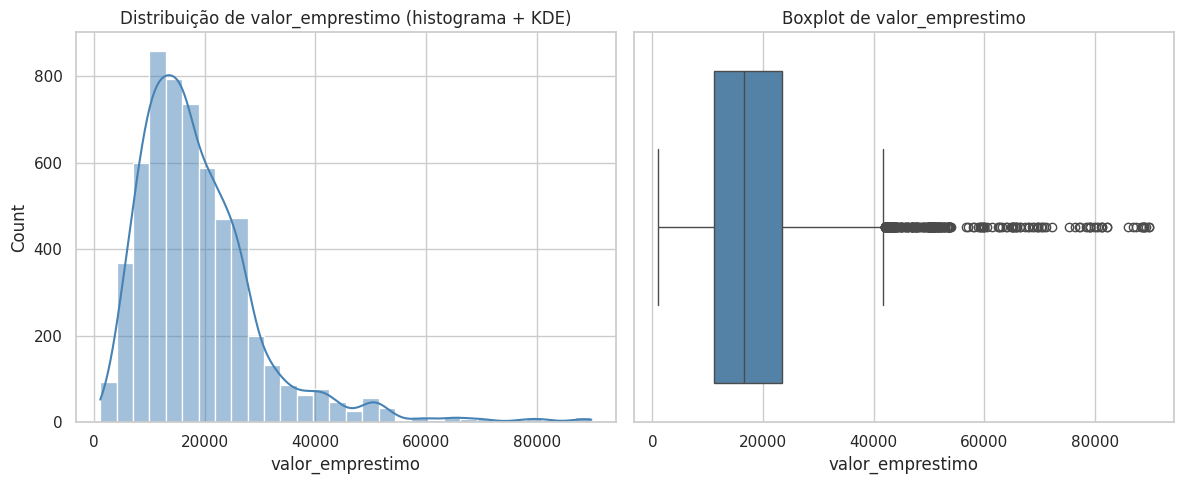


Skewness de idade_linha_credito_mais_antiga_meses: 1.36
Kurtosis (excesso) de idade_linha_credito_mais_antiga_meses: 7.84


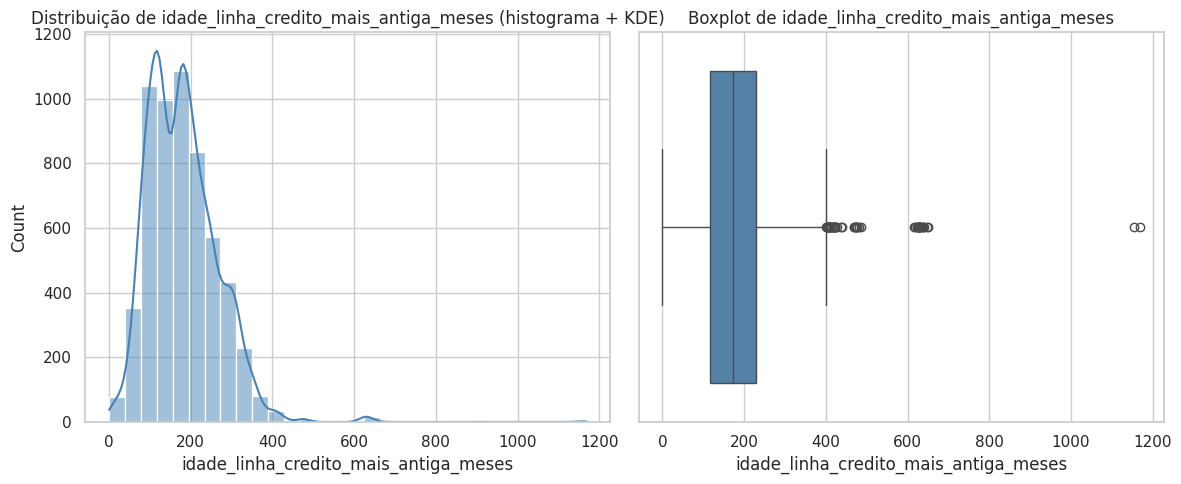


Skewness de percentual_divida_renda: 2.71
Kurtosis (excesso) de percentual_divida_renda: 50.48


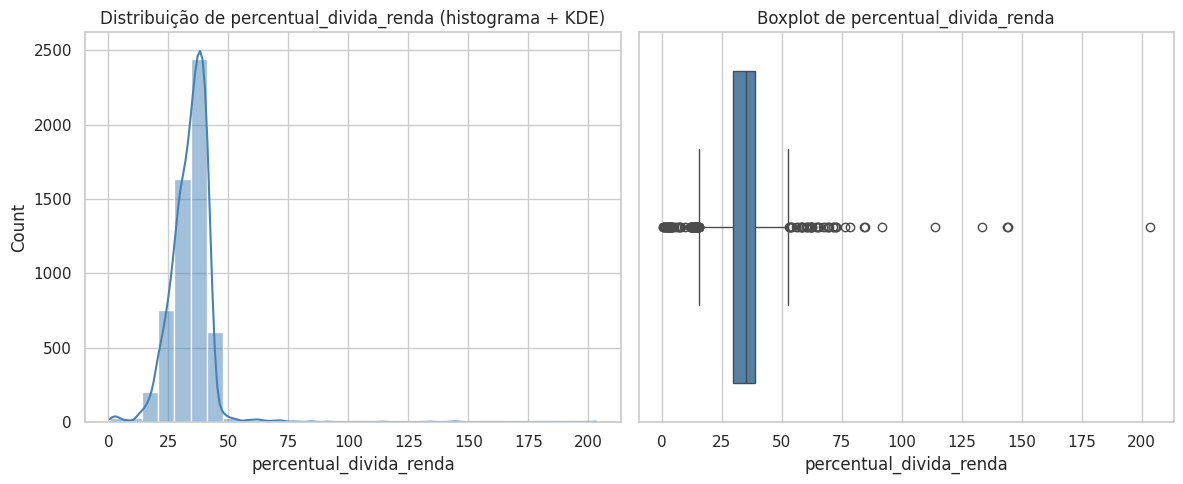

In [ ]:
# valor_emprestimo: skewness e kurtosis, com histograma + KDE e boxplot.
colunas = ["valor_emprestimo", "idade_linha_credito_mais_antiga_meses", "percentual_divida_renda"]

for col in colunas:
    skew_kurt(df, col)
    plot_dist_boxplot(df, col)
    print()

Das variáveis escolhidas, temos:
* Skewness: Maior que zeros em todas, evidenciando uma cauda mais longa a direita;
* Kurtosis: Todas maior que zero, porém, um destaque especial para **percentual_divida_renda** que com um valor de 50 evidencia um forte peso a valores extremos, quando comparada as outras duas que possuem valores menores que 10;
* Os resultados de Skewness e Kurtosis puderam ser melhor visualizados pelos gráficos gerados;

As estatísticas foram calculadas após a imputação e antes do tratamento dos outliers.

| Variável | Skewness | Excesso de curtose | Interpretação |
|---|---:|---:|---|
| Valor do empréstimo | 2,02 | 6,83 | Cauda à direita, com algumas solicitações de valores elevados. Esses valores podem ser legítimos e representam maior montante solicitado. |
| Idade da linha de crédito mais antiga | 1,36 | 7,84 | Há valores elevados, incluindo aproximadamente 1.168 meses, equivalentes a 97 anos. O registro merece conferência na fonte, sem exclusão automática. |
| Percentual dívida/renda | 2,71 | 50,48 | Forte influência de valores extremos, incluindo o máximo de 203,31%, investigado na Tarefa 9. |

Foi utilizada a definição de **excesso de curtose**, em que a distribuição normal tem referência zero. Os histogramas com KDE mostram o formato das distribuições; os boxplots evidenciam valores afastados da região central. Um ponto extremo não é, por si só, um erro de registro.

Os valores de curtose 50,48 nesta tarefa e 50,52 na comparação da Tarefa 10 decorrem das configurações diferentes de correção de viés: `scipy.stats.kurtosis()` usa `bias=True` por padrão, enquanto `pandas.Series.kurt()` aplica uma correção. Não representam uma alteração da base entre as duas medições anteriores ao tratamento.

Skewness de valor_divida_hipoteca: 1.92
Kurtosis (excesso) de valor_divida_hipoteca: 7.16


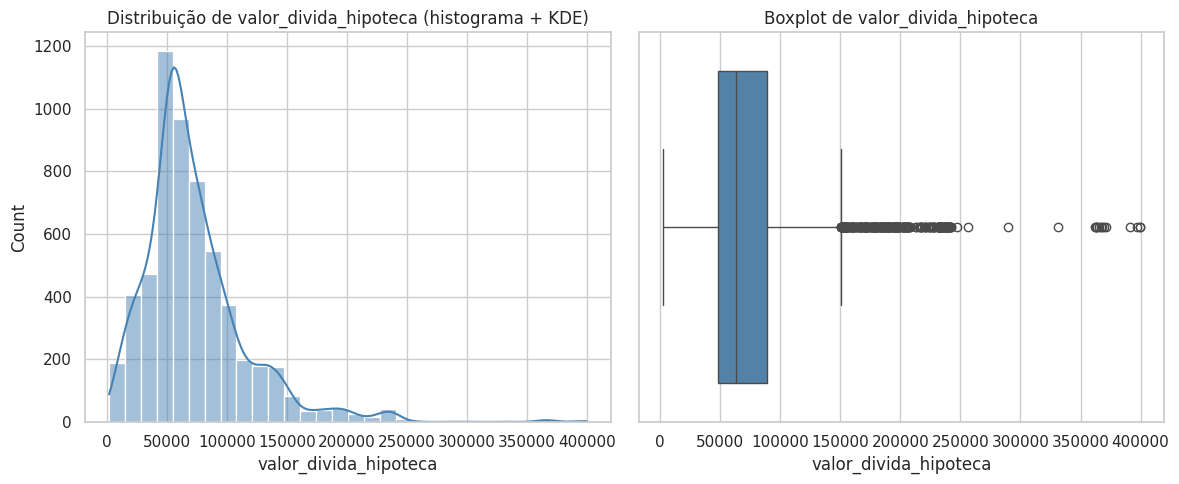


Skewness de valor_imovel: 3.09
Kurtosis (excesso) de valor_imovel: 24.65


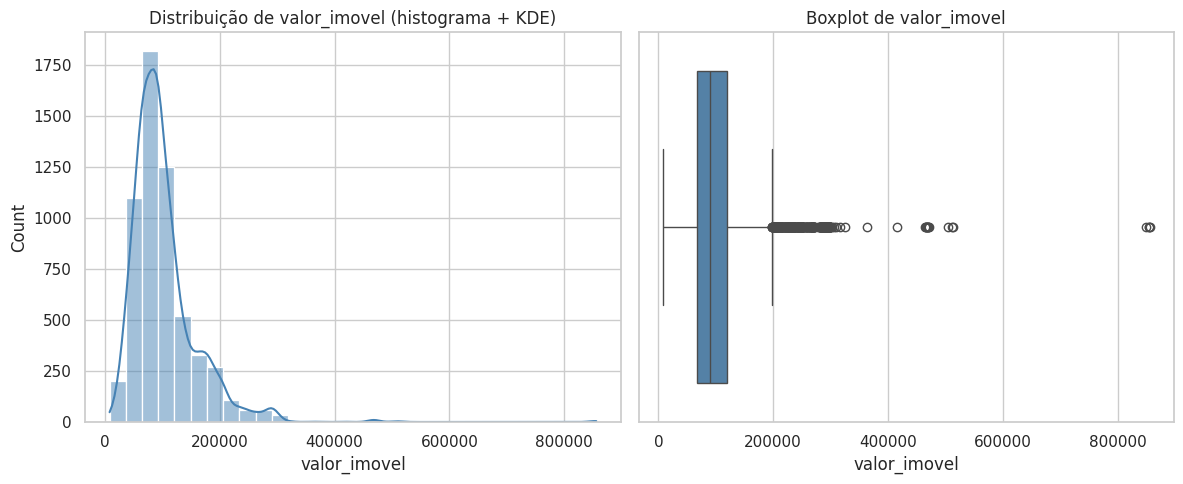


Skewness de anos_emprego_atual: 1.07
Kurtosis (excesso) de anos_emprego_atual: 0.65


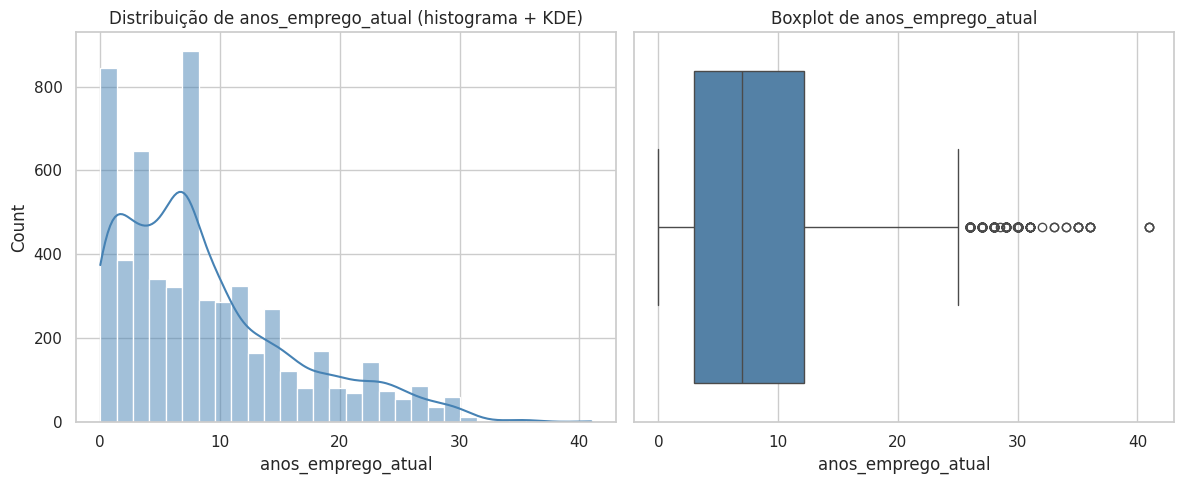

In [ ]:
# Análise das demais variáveis contínuas, que não foram escolhidas (apenas por curiosidade):
colunas = ["valor_divida_hipoteca", "valor_imovel", "anos_emprego_atual", ]

for col in colunas:
    skew_kurt(df, col)
    plot_dist_boxplot(df, col)
    print()

**Tarefa 9:**
1. Apliquem a regra do IQR e o critério de Z-Score em DEBTINC/"percentual_divida_renda" (razão dívida/renda).
2. Os dois critérios encontram a mesma quantidade de outliers?
3. Existe algum limite de regra de negócio plausível para essa variável (pensem: que valor de DEBTINC já seria, por definição, implausível)?

In [ ]:
# regra do IQR
df_outliers_iqr = outliers_iqr(df, 'percentual_divida_renda')

Q1 = 29.7 | Q3 = 39.0 | IQR = 9.3
Limite inferior = 15.7 | Limite superior = 53.0
Quantidade de outliers pela regra do IQR: 120



In [ ]:
df_outliers_iqr.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
57,1,3200.0,23159.0,89720.0,HomeImp,Mgr,20.0,0,2,117.805748,0,9,0.524499,2
92,0,4000.0,54641.0,45760.0,HomeImp,Other,0.0,0,0,173.466667,0,0,13.293199,4
118,0,4500.0,54641.0,49044.0,HomeImp,Other,0.0,0,0,173.466667,0,0,11.652739,3
216,1,5200.0,40564.0,39527.0,HomeImp,Other,0.0,0,0,157.771036,1,13,72.670433,0
220,0,5300.0,54641.0,49396.0,HomeImp,Other,0.0,0,0,173.466667,0,0,12.043671,3


In [ ]:
df_outliers_zscore = outliers_zscore(df, 'percentual_divida_renda')

Quantidade de outliers pelo critério de Z-Score (|Z| > 3): 68


Os critérios não encontraram a mesma quantidade de outliers:

O IQR identificou 120 registros, com limites de 15,65% e 52,98%.
O Z-Score identificou 68 registros, com limites aproximados de 9,55% e 58,58%.
Os 68 casos do Z-Score também foram identificados pelo IQR; portanto, o IQR encontrou 52 casos adicionais.
A diferença é esperada. O IQR usa quartis e é mais resistente à assimetria. O Z-Score depende da média e do desvio-padrão; como a distribuição tem uma cauda direita extrema, chegando a 203,31%, o desvio-padrão aumenta e o critério fica menos sensível.

Quanto à regra de negócio, uma razão dívida/renda negativa seria impossível. Um valor acima de 100% não é matematicamente impossível, mas indica obrigações de dívida superiores à renda declarada e é operacionalmente crítico ou possivelmente inconsistente. Por isso, adotamos 100% como limite de validação e revisão, não como justificativa automática para excluir o cliente. Foram encontrados 5 registros acima desse valor. Os 74 valores abaixo do limite inferior do IQR foram mantidos, pois uma razão dívida/renda baixa é perfeitamente plausível.

**Tarefa 10:** Escolham um tratamento para os outliers encontrado (winsorization, transformação logarítmica, ou exclusão justificada) e apliquem.

Foi escolhida a winsorização unilateral pelo limite de negócio de 100%. Ela preserva todas as linhas e a informação de alto risco, mas impede que cinco valores extremos dominem médias, correlações e gráficos. A cauda inferior não será alterada, pois valores baixos de dívida/renda são válidos.

Registros winsorizados: 5


,Antes,Depois
Mínimo,0.52,0.52
Máximo,203.31,100.00
Média,34.07,34.02
Desvio-padrão,8.17,7.65
Skewness,2.71,0.39
Kurtosis,50.52,8.00


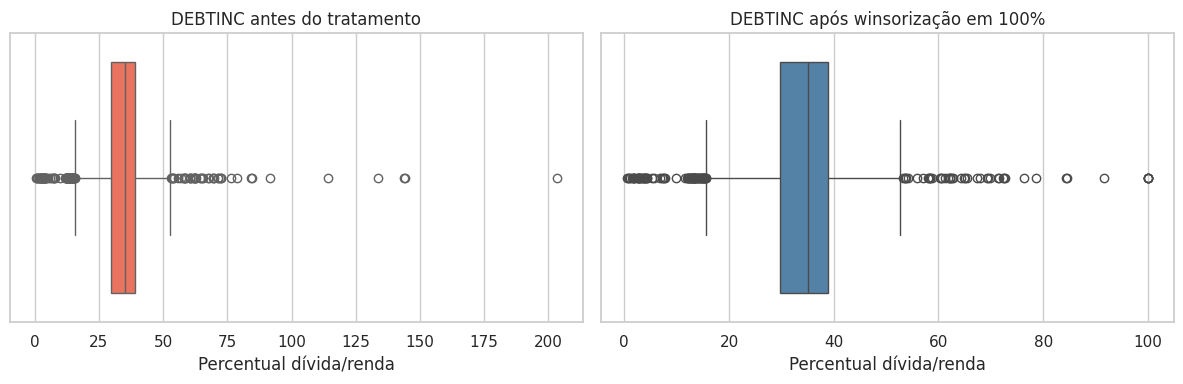

In [ ]:
# O DataFrame original tratado até a Tarefa 9 permanece em `df`.
# As análises seguintes usam uma cópia com o tratamento de outliers.
df_tratado = df.copy()
coluna_dti = 'percentual_divida_renda'
antes = df_tratado[coluna_dti].copy()
df_tratado[coluna_dti] = df_tratado[coluna_dti].clip(lower=0, upper=100)
depois = df_tratado[coluna_dti]

comparacao_tratamento = pd.DataFrame(
    {
        "Antes": [antes.min(), antes.max(), antes.mean(), antes.std(), antes.skew(), antes.kurt()],
        "Depois": [depois.min(), depois.max(), depois.mean(), depois.std(), depois.skew(), depois.kurt()],
    },
    index=["Mínimo", "Máximo", "Média", "Desvio-padrão", "Skewness", "Kurtosis"],
)

print(f"Registros winsorizados: {(antes != depois).sum()}")
display(comparacao_tratamento.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=antes, ax=axes[0], color="tomato")
axes[0].set_title("DEBTINC antes do tratamento")
axes[0].set_xlabel("Percentual dívida/renda")

sns.boxplot(x=depois, ax=axes[1], color="steelblue")
axes[1].set_title("DEBTINC após winsorização em 100%")
axes[1].set_xlabel("Percentual dívida/renda")

plt.tight_layout()
plt.show()

A winsorização alterou somente 5 de 5.768 registros (0,09%). O máximo caiu de 203,31% para 100%, a assimetria caiu de aproximadamente 2,71 para 0,39 e nenhuma observação foi removida. Em um processo real, esses cinco casos também deveriam ser encaminhados para conferência da renda e das obrigações informadas.

# **Bloco 4 - Bivariada, Multivariada e Feature Engineering:**

**Tarefa 11:**
1. Calculem a correlação (Pearson e Spearman) entre as variáveis numéricas e o alvo BAD.
2. Qual variável está mais associada à inadimplência?
3. Isso já é prova de causalidade?

In [ ]:
# 11.1
# Seleciona apenas variáveis numéricas
cols_num = df_tratado.select_dtypes(include="number").columns.tolist()
# Remove a variável alvo
cols_pred = [c for c in cols_num if c != "target_inadimplencia"]
# Correlação de Pearson
corr_pearson = (
df_tratado[cols_pred + ["target_inadimplencia"]]
.corr(method="pearson")["target_inadimplencia"]
.drop("target_inadimplencia")
.sort_values(key=abs, ascending=False)
)
# Correlação de Spearman
corr_spearman = (
df_tratado[cols_pred + ["target_inadimplencia"]]
.corr(method="spearman")["target_inadimplencia"]
.drop("target_inadimplencia")
.sort_values(key=abs, ascending=False)
)
display(corr_pearson.to_frame("Pearson"))
display(corr_spearman.to_frame("Spearman"))

,Pearson
qtd_linhas_credito_atrasadas,0.356365
qtd_registros_credito_negativos,0.277253
qtd_consultas_credito_recentes,0.174282
qtd_nulos_linha,0.169057
idade_linha_credito_mais_antiga_meses,-0.168611
percentual_divida_renda,0.158113
valor_emprestimo,-0.072469
anos_emprego_atual,-0.059318
valor_divida_hipoteca,-0.045411
valor_imovel,-0.036838


,Spearman
qtd_linhas_credito_atrasadas,0.335713
qtd_nulos_linha,0.286167
qtd_registros_credito_negativos,0.276198
idade_linha_credito_mais_antiga_meses,-0.184550
qtd_consultas_credito_recentes,0.143316
percentual_divida_renda,0.113502
valor_emprestimo,-0.106056
valor_imovel,-0.075944
valor_divida_hipoteca,-0.072558
anos_emprego_atual,-0.058560


**Questão 11.2: Qual variável está mais associada à inadimplência?**

A variável mais associada à inadimplência será aquela que apresentar o maior valor absoluto de correlação com a variável alvo target_inadimplencia. Conforme a análise exploratória realizada anteriormente, espera-se que a variável percentual_divida_renda (DEBTINC) esteja entre as mais relevantes, pois representa o comprometimento da renda do cliente com dívidas e tende a aumentar o risco financeiro. Entretanto, a resposta final deve considerar os resultados efetivamente obtidos na execução do cálculo das correlações.

A variável mais associada à inadimplência nos dois critérios foi `qtd_linhas_credito_atrasadas`, com Pearson de **0,3564** e Spearman de **0,3357**. Entre as variáveis originais, `qtd_registros_credito_negativos` também se destaca, com Pearson de **0,2773** e Spearman de **0,2762**.

`percentual_divida_renda` apresentou Pearson de **0,1581** e Spearman de **0,1135**, portanto não foi a variável mais associada ao alvo. A idade da linha de crédito mais antiga apresentou associação negativa: **−0,1686** em Pearson e **−0,1846** em Spearman.

Considerando também a coluna criada `qtd_nulos_linha`, ela ocupa a segunda posição em Spearman, com **0,2862**. Essa medida de completude do registro merece investigação própria e não deve ser confundida com uma característica financeira original do cliente.

**Questão 11.3: Isso é prova de causalidade?**

Não. Correlação não implica causalidade. Mesmo que uma variável apresente forte correlação com a inadimplência, isso indica apenas que existe associação estatística entre elas. Não é possível afirmar que uma variável causa diretamente a outra. Por exemplo, clientes com maior percentual de dívida em relação à renda podem apresentar maior taxa de inadimplência, mas outros fatores também podem influenciar esse comportamento, como: Nível de renda; Histórico de crédito; Situação de emprego; Condições econômicas externas. Portanto, a análise de correlação é útil para identificar variáveis potencialmente importantes para modelos preditivos, mas não para estabelecer relações de causa e efeito.

**Tarefa 12:** Comparem DEBTINC (ou outra variável contínua à escolha) entre os grupos BAD == 0 e BAD == 1 com boxplot ou violin plot.

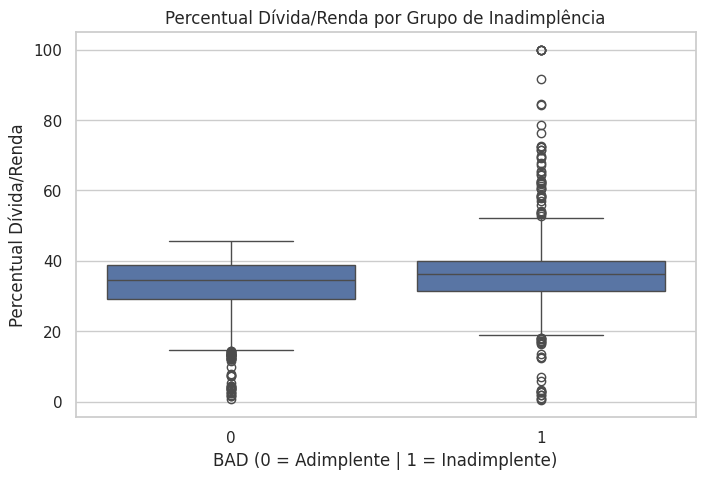

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.boxplot(
data=df_tratado,
x="target_inadimplencia",
y="percentual_divida_renda"
)
plt.title("Percentual Dívida/Renda por Grupo de Inadimplência")
plt.xlabel("BAD (0 = Adimplente | 1 = Inadimplente)")
plt.ylabel("Percentual Dívida/Renda")
plt.show()

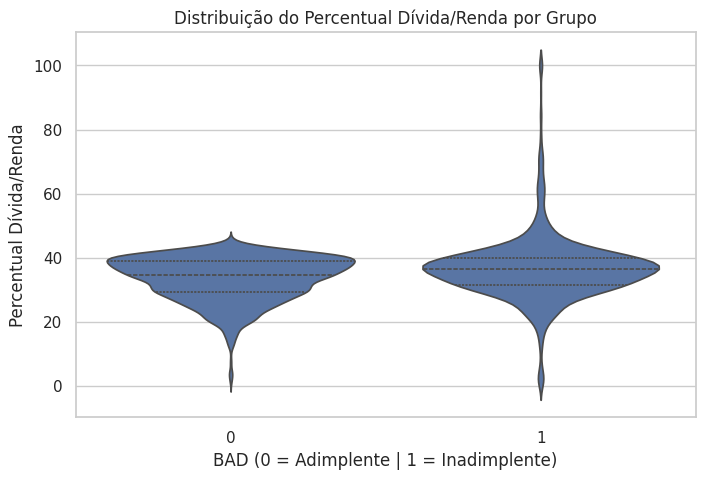

In [ ]:
plt.figure(figsize=(8,5))
sns.violinplot(
data=df_tratado,
x="target_inadimplencia",
y="percentual_divida_renda",
inner="quartile"
)
plt.title("Distribuição do Percentual Dívida/Renda por Grupo")
plt.xlabel("BAD (0 = Adimplente | 1 = Inadimplente)")
plt.ylabel("Percentual Dívida/Renda")
plt.show()

Ao comparar a distribuição da variável percentual_divida_renda (DEBTINC) entre os grupos de clientes adimplentes (BAD = 0) e inadimplentes (BAD = 1), verifica-se se existe diferença relevante no comprometimento da renda com dívidas entre os dois grupos.

O grupo BAD = 1 apresenta:
1. Mediana mais elevada;
2. Quartis superiores maiores;
3. Maior concentração de valores altos;

isso indica que clientes inadimplentes tendem a possuir maior comprometimento financeiro, o que sugere uma relação entre aumento da razão dívida/renda e maior risco de inadimplência, pois interpretando os números temos que os 4.629 adimplentes apresentaram média de DEBTINC de 33,42% e mediana de 34,69%. Entre os 1.139 inadimplentes, a média foi de 36,46% e a mediana de 36,33%. Há ampla sobreposição das distribuições, portanto DEBTINC isoladamente não separa adequadamente todos os clientes. A comparação inclui valores imputados. No violin plot, a KDE pode se estender além dos valores observados; essa extensão é efeito da suavização, e não a existência de registros adicionais.

**Tarefa 13:** Cruzem REASON x JOB com pd.crosstab() e testem associação com chi2_contingency().

In [ ]:
tabela = pd.crosstab(df_tratado['categoria_ocupacional'], df_tratado['motivo_emprestimo'])
print("Tabela de contingência (Motivo Empréstimo x Categoria Ocupacional):")
display(tabela)

chi2, p_valor, graus_liberdade, valores_esperados = stats.chi2_contingency(tabela)

print()
print(f"p-valor: {p_valor:.4f}")

Tabela de contingência (Motivo Empréstimo x Categoria Ocupacional):


motivo_emprestimo,DebtCon,HomeImp
categoria_ocupacional,,
Mgr,582,170
Office,643,299
Other,1774,732
ProfExe,868,400
Sales,97,12
Self,78,113



p-valor: 0.0000


O teste confirmou `p < 0,5` que o motivo do empréstimo está relacionado à categoria ocupacional do cliente. Profissionais autônomos, por exemplo, demonstram uma tendência significativa maior a buscar crédito para reformas residenciais em comparação com profissionais de vendas, que buscam prioritariamente a consolidação de dívidas.

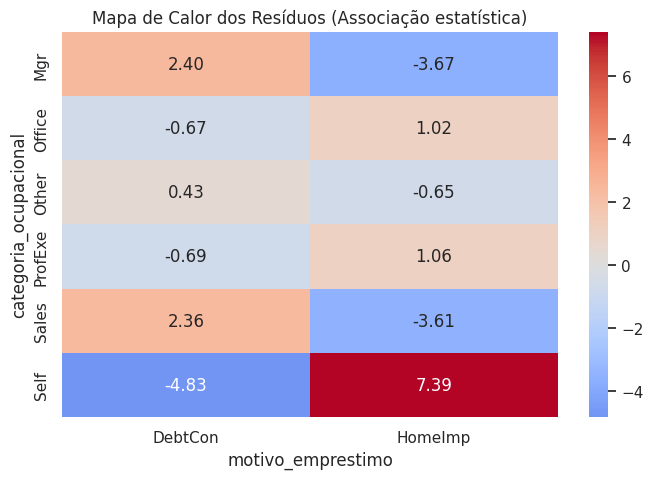

In [ ]:
residuos = (tabela.values - valores_esperados) / np.sqrt(valores_esperados)
df_residuos = pd.DataFrame(residuos, index=tabela.index, columns=tabela.columns)

plt.figure(figsize=(8, 5))
sns.heatmap(df_residuos, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Mapa de Calor dos Resíduos (Associação estatística)')
plt.show()

O gráfico mostra que existe associação nas categorias Profissionais Autônomos `Self`, Gerentes `Mgr` e  Vendedores `Sales`.

**Tarefa 14:** Feature engineering (adaptado, já que o HMEQ não tem coluna de
data): criem pelo menos uma variável nova a partir das existentes — por exemplo, uma faixa categórica de DEBTINC com pd.cut() , ou uma razão nova como LOAN / VALUE (quanto do valor do imóvel o empréstimo
representa). Justifiquem por que essa variável poderia ajudar a explicar BAD.

In [ ]:
df_tratado["percentual_imovel_garantia"] = (df_tratado["valor_emprestimo"] / df_tratado["valor_imovel"]) * 100

df_tratado["percentual_imovel_garantia"]

,percentual_imovel_garantia
0,2.818706
1,1.900585
2,8.982036
4,1.517857
5,4.216270
...,...
5955,98.575151
5956,95.763797
5957,95.992424
5958,97.756393


Foi criada a variável`percentual_imovel_garantia`, calculada a partir da razão entre o valor do empréstimo solicitado `valor_emprestimo` e o valor do imóvel `valor_imovel`, expressa em percentual. Essa variável indica quanto do valor do imóvel está representado pelo empréstimo. Valores mais elevados indicam que o empréstimo representa uma parcela maior do valor da garantia, podendo indicar maior exposição ao risco de crédito. Portanto, essa característica pode contribuir para explicar a variável `target_inadimplencia`, uma vez que níveis elevados dessa razão podem estar associados a uma maior probabilidade de inadimplência.

Além da coluna `percentual_imovel_garantia`, foi criada a `faixa_percentual_garantia` que divide os valores em faixas.

,faixa_percentual_garantia,target_inadimplencia
0,Até 25%,20.358868
1,25%–50%,18.589133
2,50%–75%,16.450216
3,75%–100%,14.728682
4,>100%,16.666667


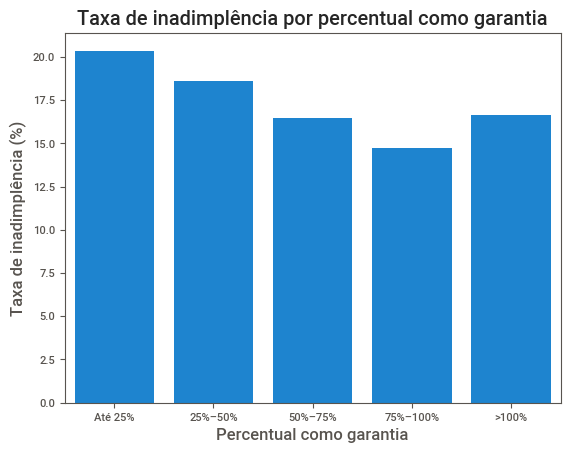

In [ ]:
df_tratado["faixa_percentual_garantia"] = pd.cut(
    df_tratado["percentual_imovel_garantia"],
    bins=[0, 25, 50, 75, 100, float("inf")],
    labels=["Até 25%", "25%–50%", "50%–75%", "75%–100%", ">100%"]
)

taxa_bad = (
    df_tratado.groupby("faixa_percentual_garantia", observed=False)["target_inadimplencia"]
      .mean()
      .mul(100)
      .reset_index()
)

display(taxa_bad)

sns.barplot(
    data=taxa_bad,
    x="faixa_percentual_garantia",
    y="target_inadimplencia"
)

plt.xlabel("Percentual como garantia")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Taxa de inadimplência por percentual como garantia")
plt.show()

Existe uma tendência de redução da taxa de inadimplência à medida que o percentual como garantia aumenta, até a faixa de 75%–100%. Nessa faixa, a taxa é a menor, aproximadamente 14,7%.

Na faixa acima de 100%, entretanto, ocorre uma pequena elevação, chegando a aproximadamente 16,7%. Portanto, não parece existir uma relação simples do tipo "quanto maior o percentual, maior a inadimplência.

Também foi criada a variável `percentual_divida_imovel` calculada a partir da razão entre o valor da hipotéca `valor_divida_hipoteca` e o valor do imóvel `valor_imovel`, expressa em percentual. Essa variável indica quanto do valor do imóvel ainda é devido. Essa valor pode contribuir para explicar a variável target_inadimplencia, uma vez que níveis elevados dessa razão podem estar associados a uma maior probabilidade de inadimplência.

Além da coluna `percentual_divida_imovel`, foi criada a `faixa_percentual_divida_imovel` que divide os valores em faixas.


,faixa_percentual_divida_imovel,target_inadimplencia
0,Até 25%,21.025641
1,25%–50%,23.742455
2,50%–75%,20.235294
3,75%–100%,17.127322
4,>100%,26.959248


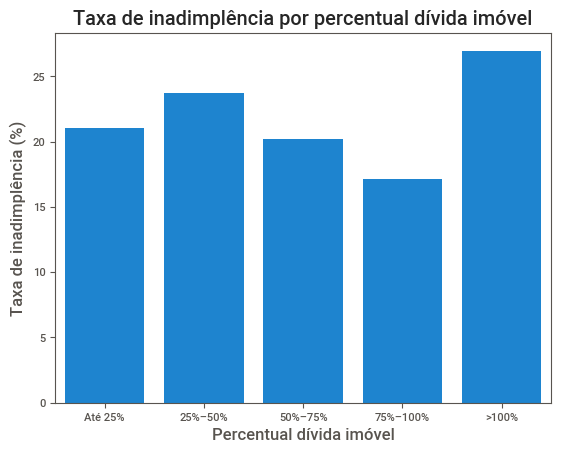

In [ ]:
df_tratado['percentual_divida_imovel'] = (df_tratado['valor_divida_hipoteca'] / df_tratado['valor_imovel']) * 100

df_tratado["faixa_percentual_divida_imovel"] = pd.cut(
    df_tratado["percentual_divida_imovel"],
    bins=[0, 25, 50, 75, 100, float("inf")],
    labels=["Até 25%", "25%–50%", "50%–75%", "75%–100%", ">100%"]
)

taxa_bad = (
    df_tratado.groupby("faixa_percentual_divida_imovel", observed=False)["target_inadimplencia"]
      .mean()
      .mul(100)
      .reset_index()
)

taxa_bad = (
    df_tratado.groupby("faixa_percentual_divida_imovel", observed=False)["target_inadimplencia"]
      .mean()
      .mul(100)
      .reset_index()
)

display(taxa_bad)

sns.barplot(
    data=taxa_bad,
    x="faixa_percentual_divida_imovel",
    y="target_inadimplencia"
)

plt.xlabel("Percentual dívida imóvel")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Taxa de inadimplência por percentual dívida imóvel")
plt.show()

O gráfico revela um comportamento não-linear do risco de crédito, destacando que a taxa de inadimplência atinge seu ápice em aproximadamente 27% na faixa acima de 100%. O risco oscila nas faixas iniciais e apresenta uma queda acentuada para cerca de 17% na janela de 75%–100%

# **Bloco 5 - EDA Automatizada e Storytelling**

**Tarefa 15:**
1. Rodem ydata-profiling ou sweetviz sobre a base tratada e comparem com o que vocês encontraram manualmente.
2. O relatório automático revelou algo que vocês não tinham notado?

Vamos gerar o relatório automático com Sweetviz sobre a base tratada e compará-lo com a EDA manual. Incluímos um indicador de ausência original de DEBTINC, pois o preenchimento dos valores não deve apagar essa informação. O indicador será usado para análise de qualidade, sem modificar DEBTINC.

In [ ]:
# Instala Sweetviz
try:
    import sweetviz as sv
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "sweetviz==2.3.2"])
    import sweetviz as sv

df_relatorio = df_tratado.copy()
# O notebook preserva o índice da base original.
df_relatorio["debtinc_ausente_original"] = (
    df_original["DEBTINC"].reindex(df_relatorio.index).isna()
)
relatorio_sweetviz = sv.analyze(
    df_relatorio,
    target_feat="target_inadimplencia",
    pairwise_analysis="on"
)
relatorio_sweetviz.show_html(
    filepath="relatorio_hmeq_sweetviz.html",
    open_browser=False,
    layout="vertical"
)
print("Relatório gerado: relatorio_hmeq_sweetviz.html")

                                             |          | [  0%]   00:00 -> (? left)

Report relatorio_hmeq_sweetviz.html was generated.
Relatório gerado: relatorio_hmeq_sweetviz.html


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



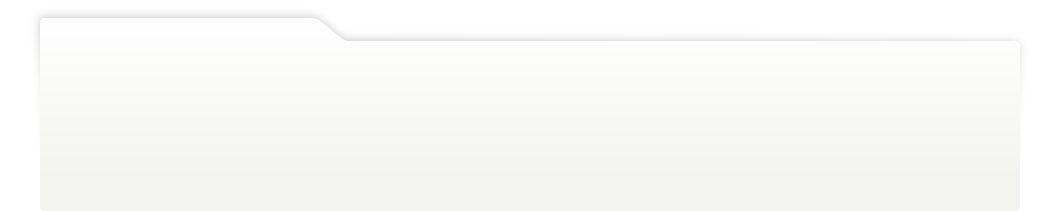
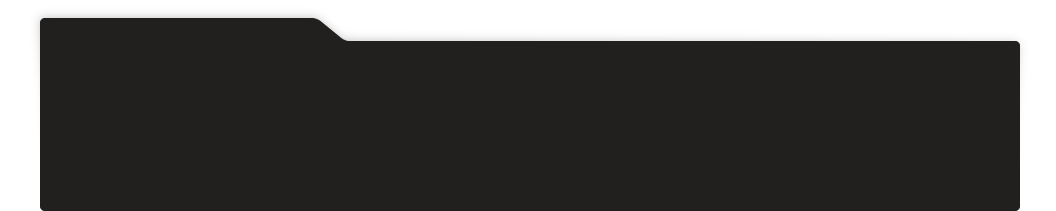
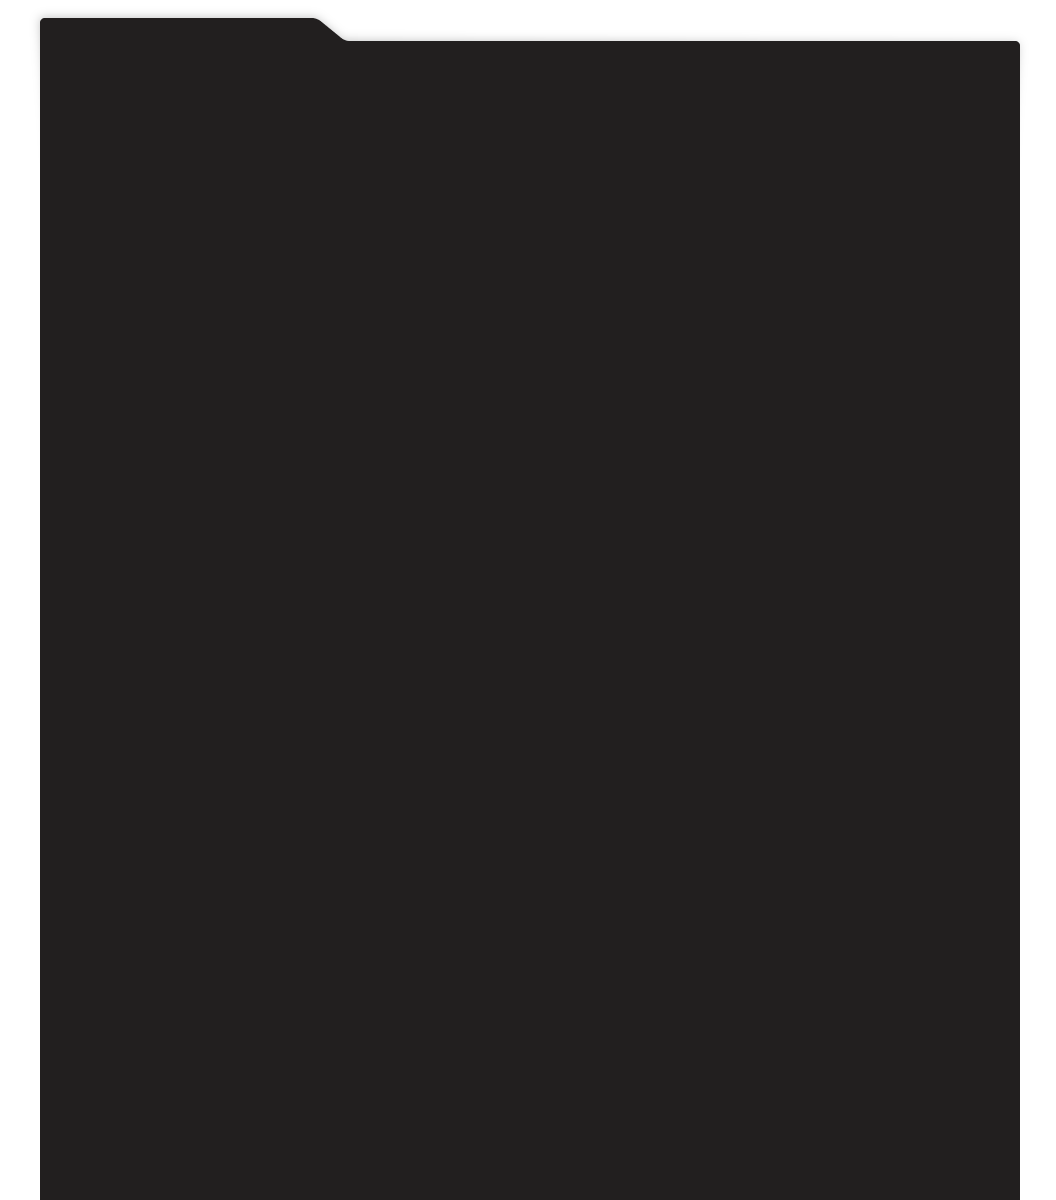
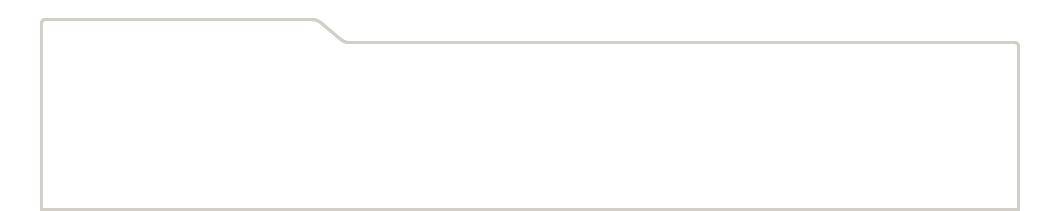
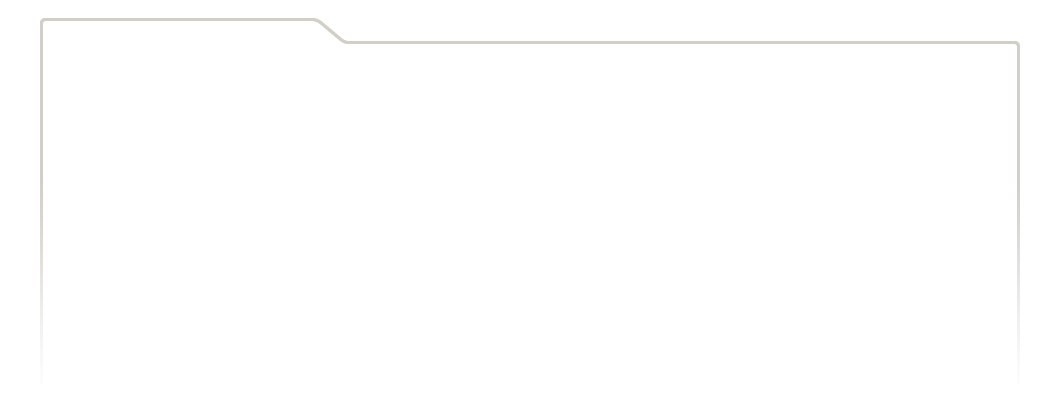
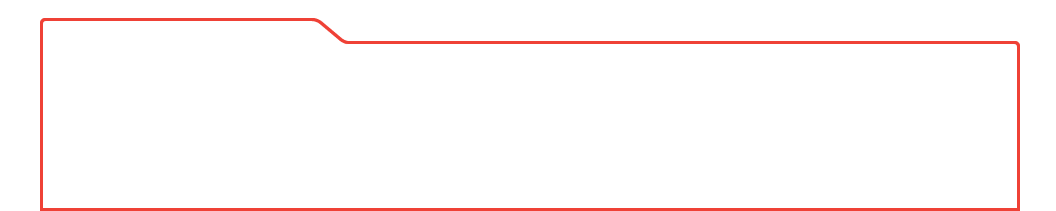
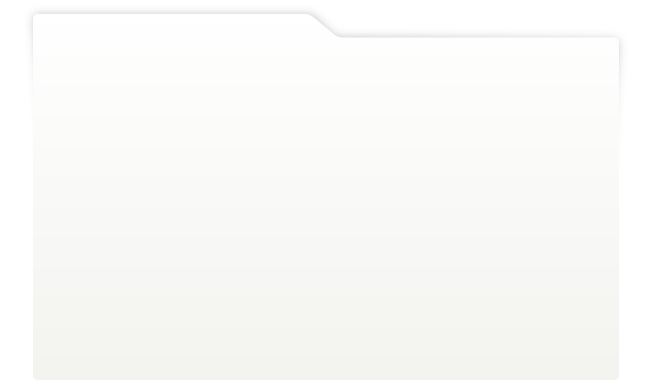
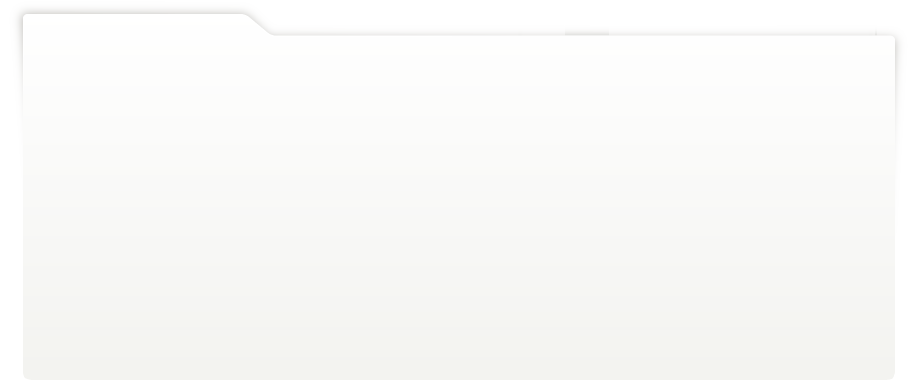
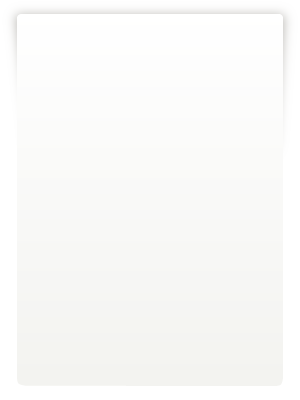
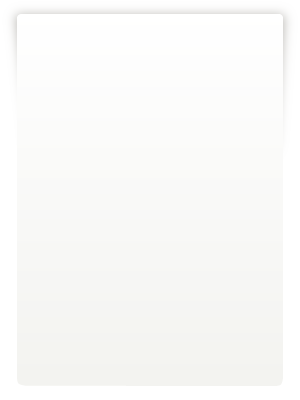
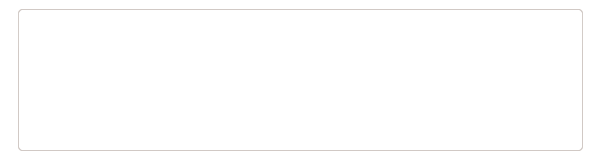
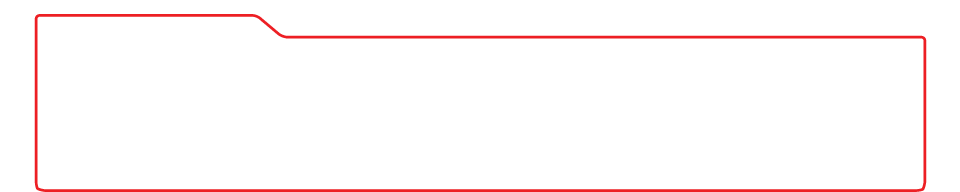
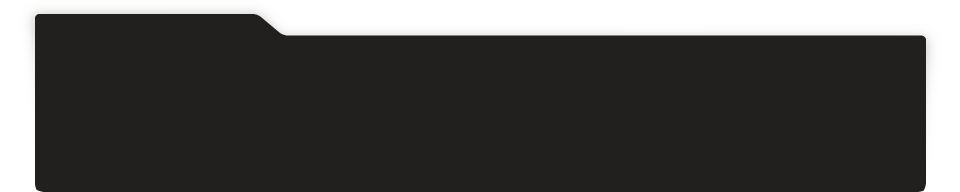
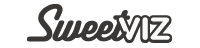
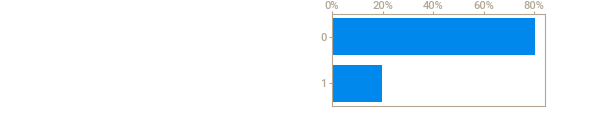
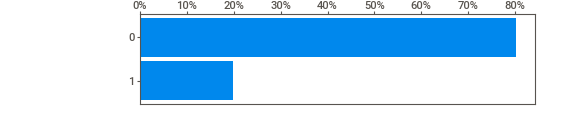
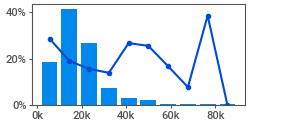
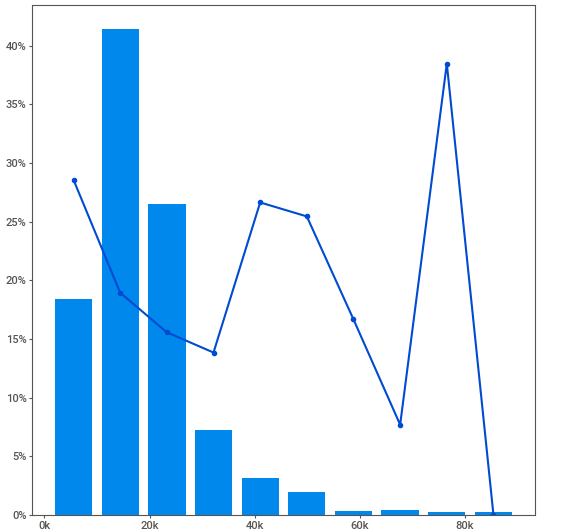
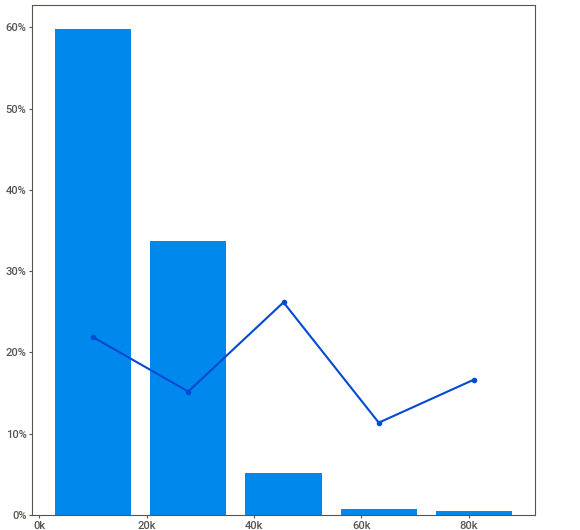
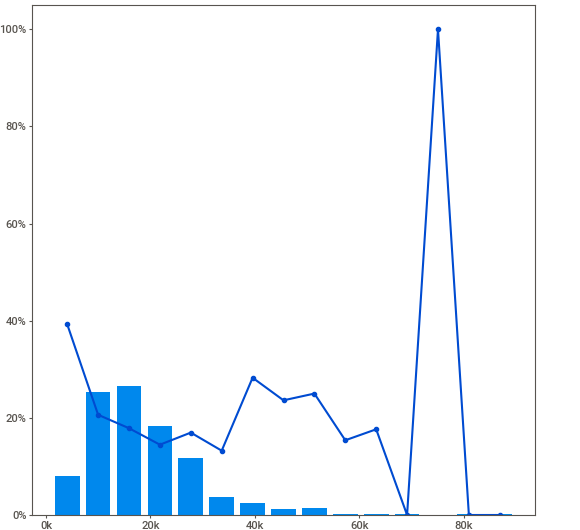
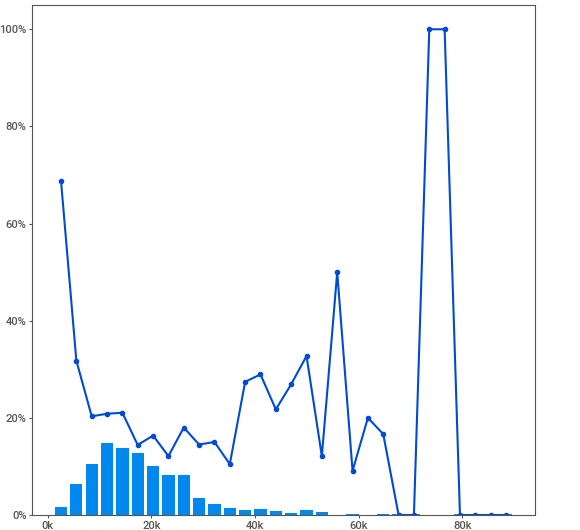
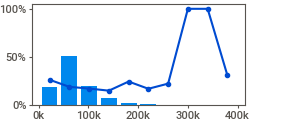
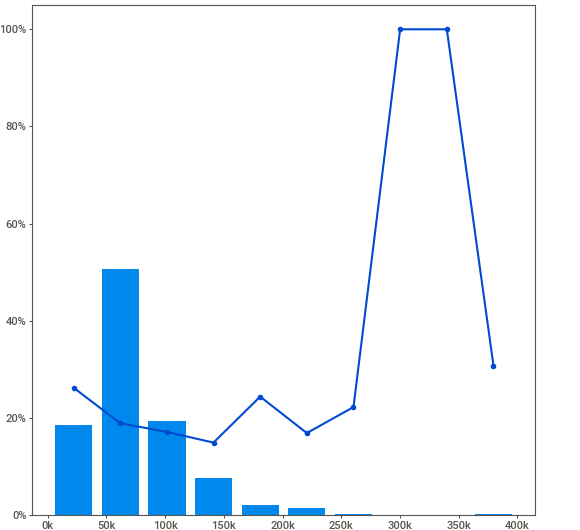
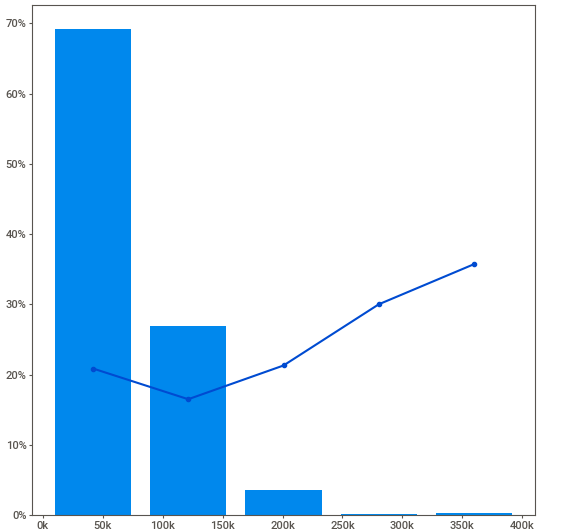
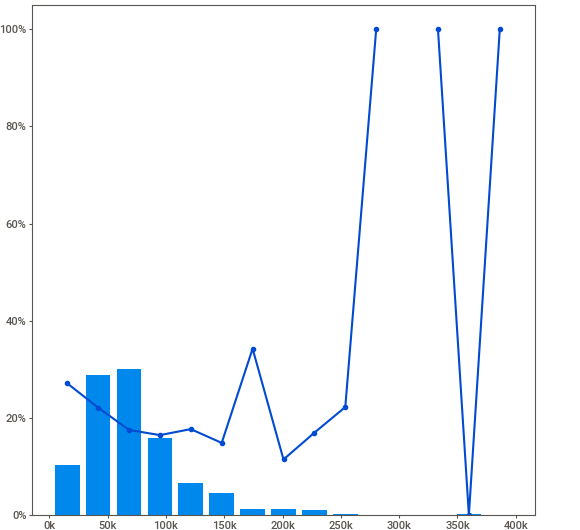
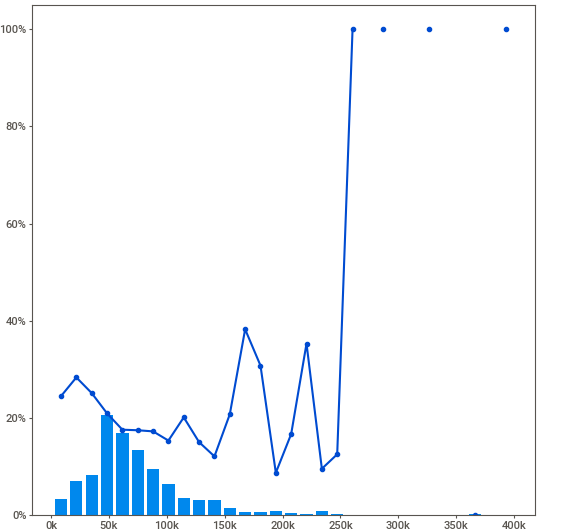
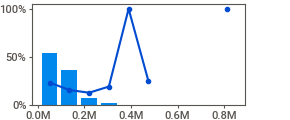
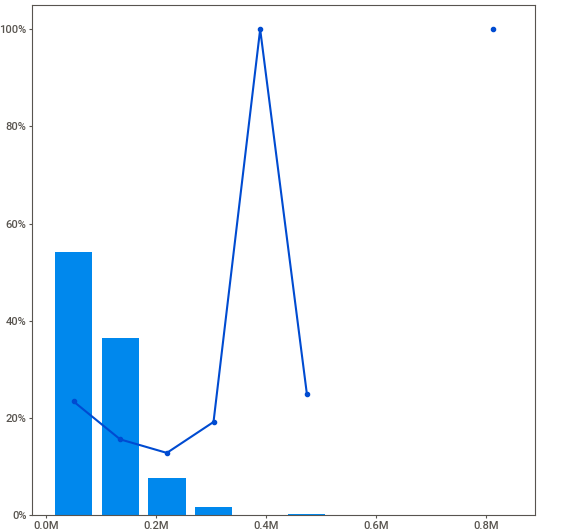
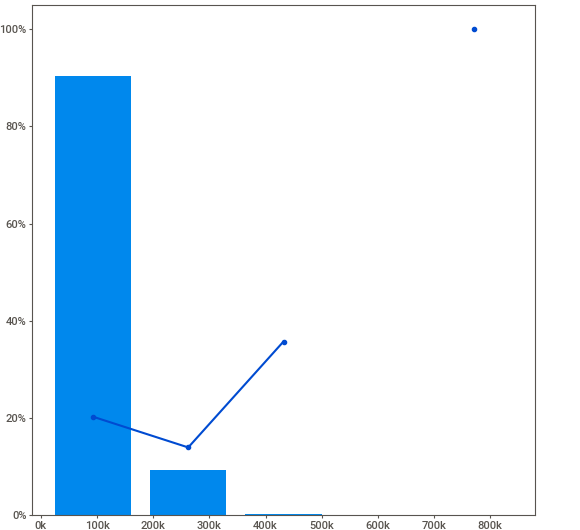
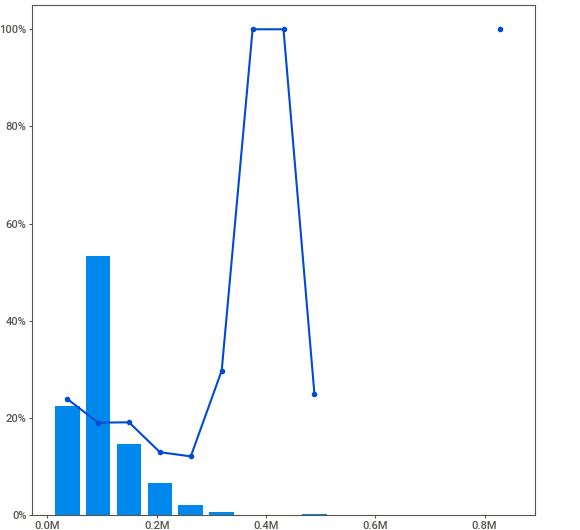
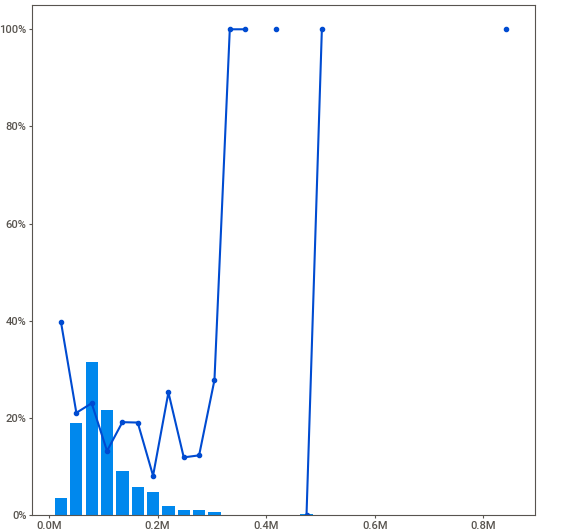
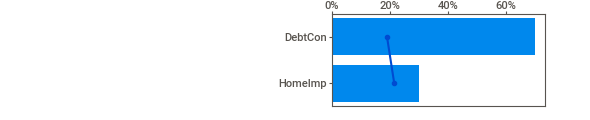
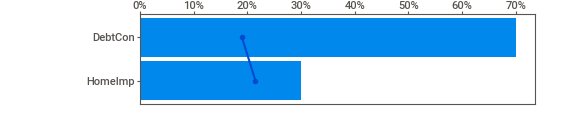
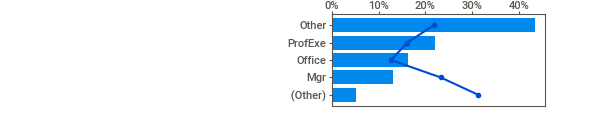
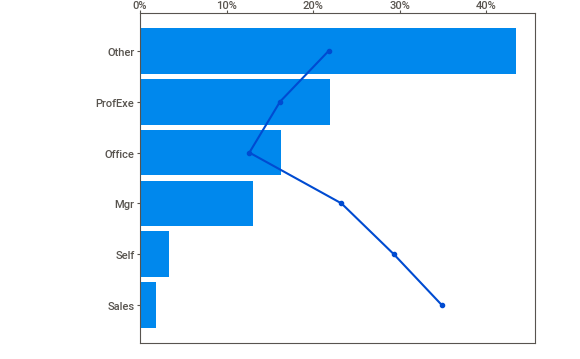
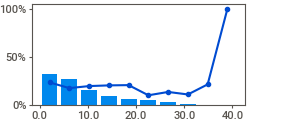
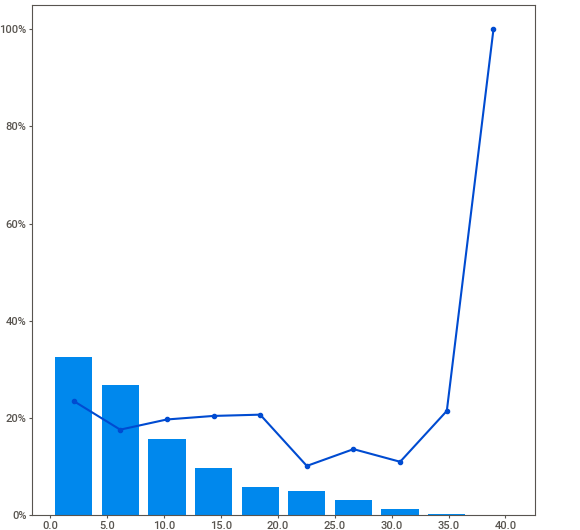
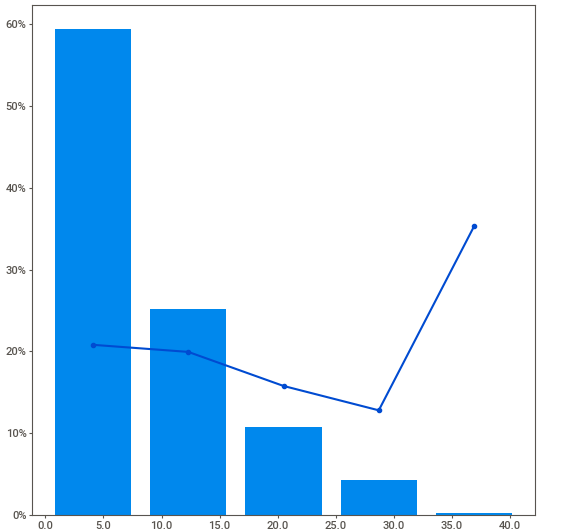
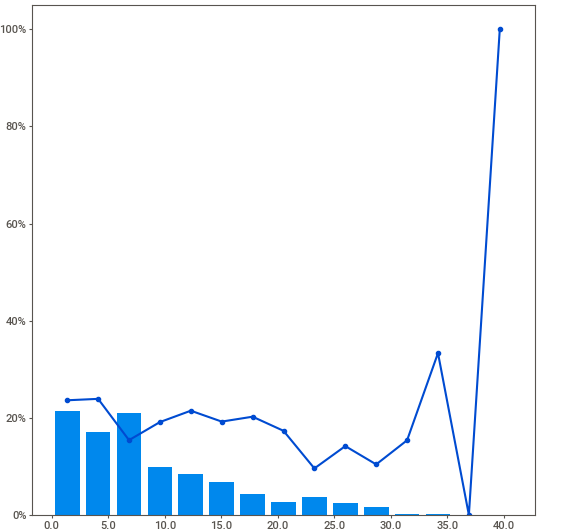
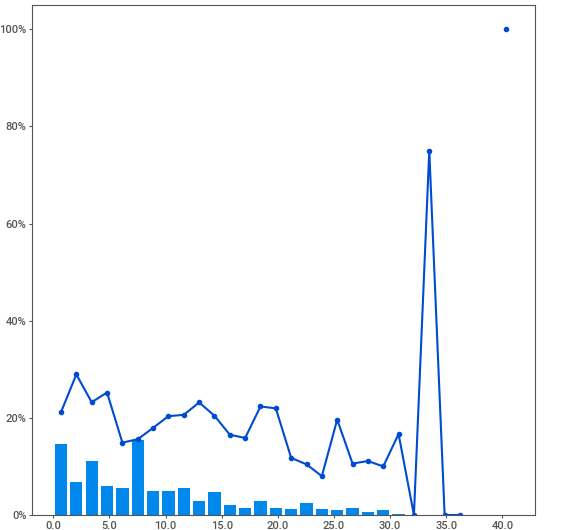
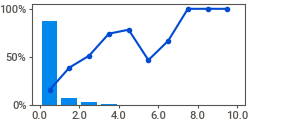
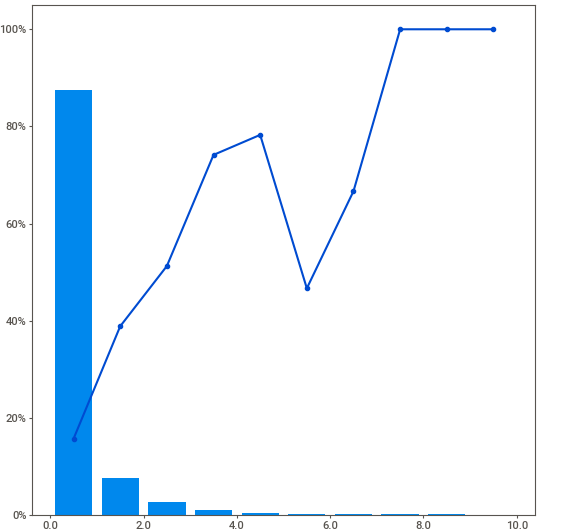
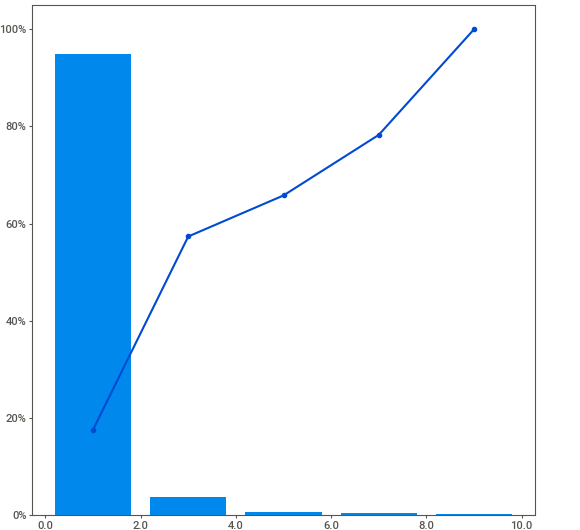
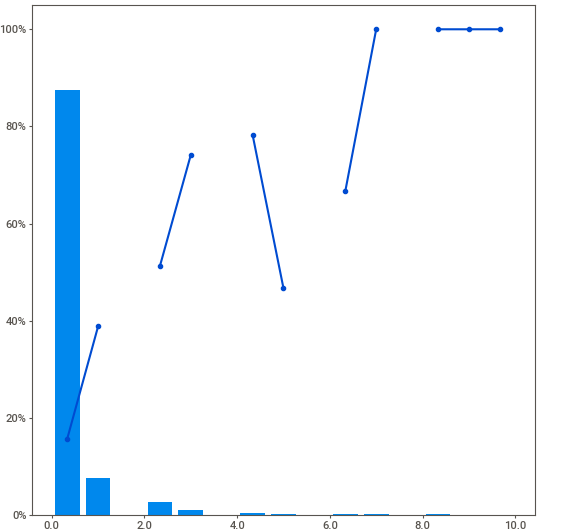
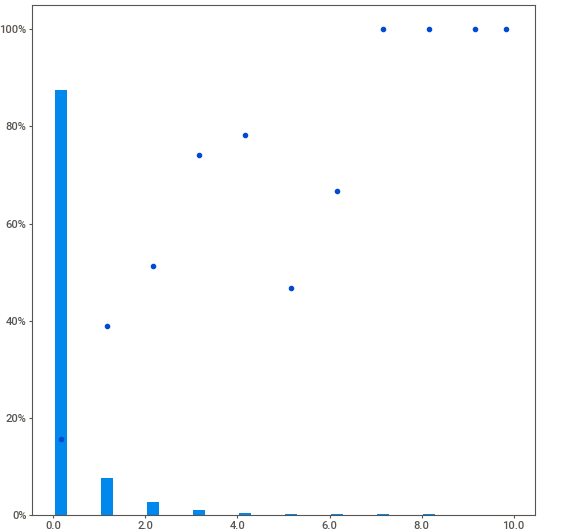
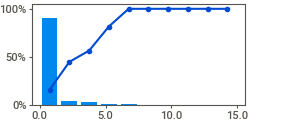
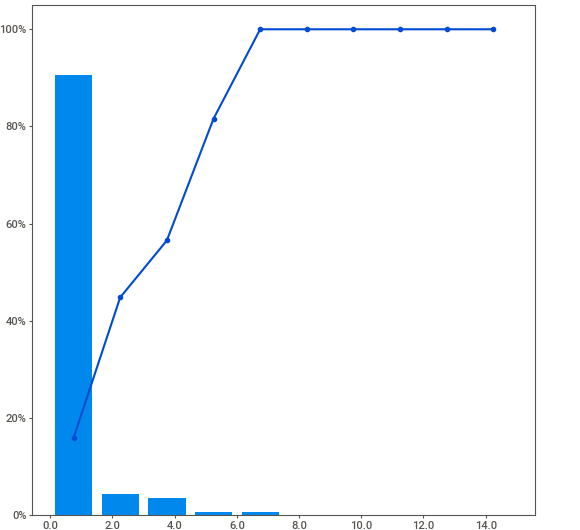
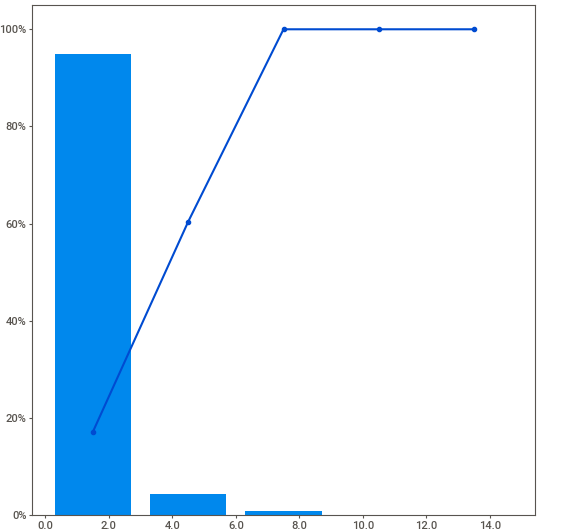
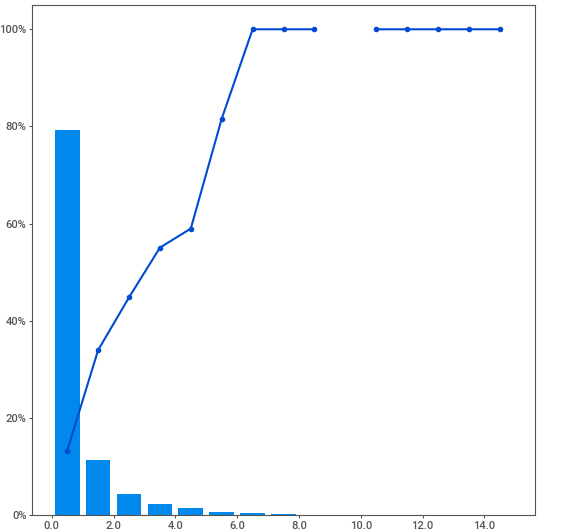
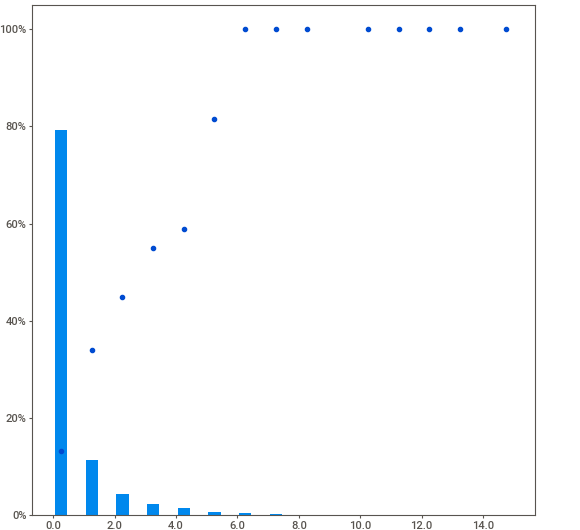
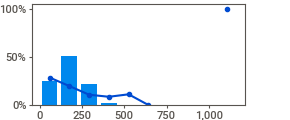
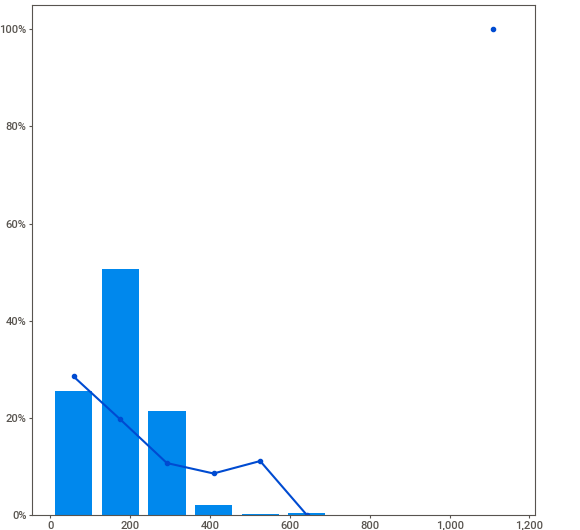
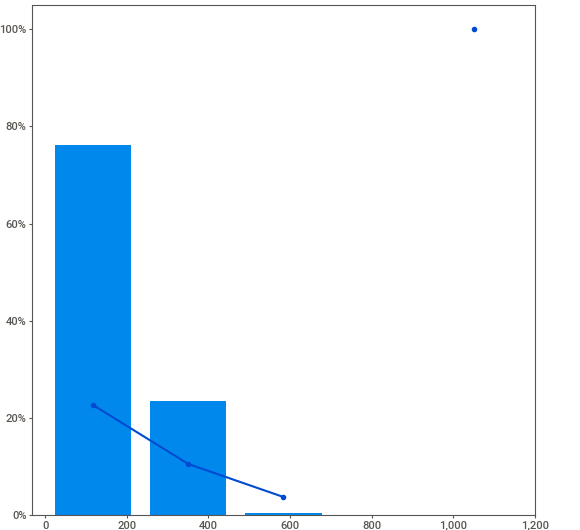
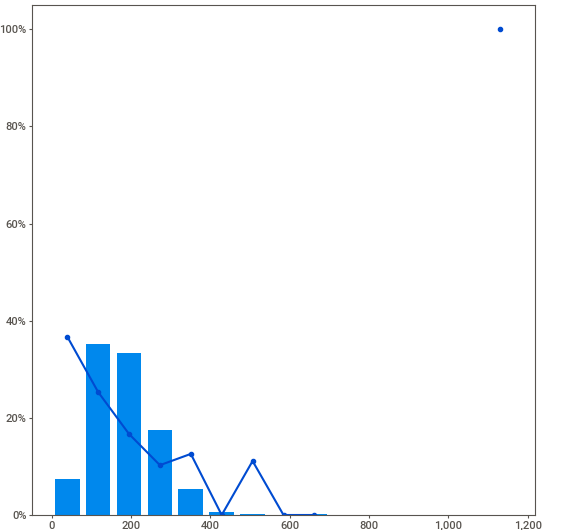
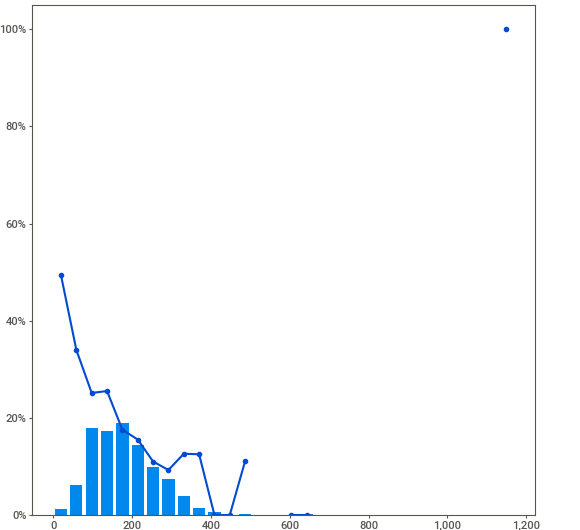
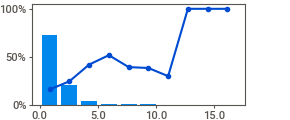
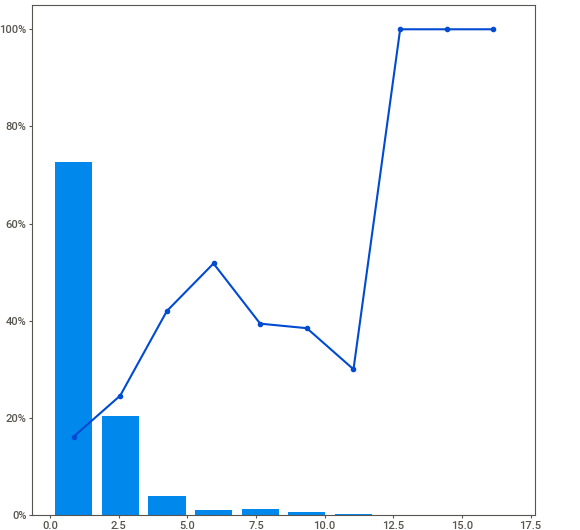
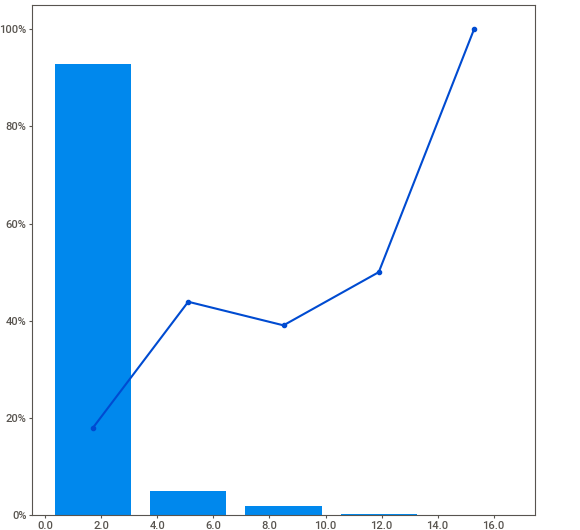
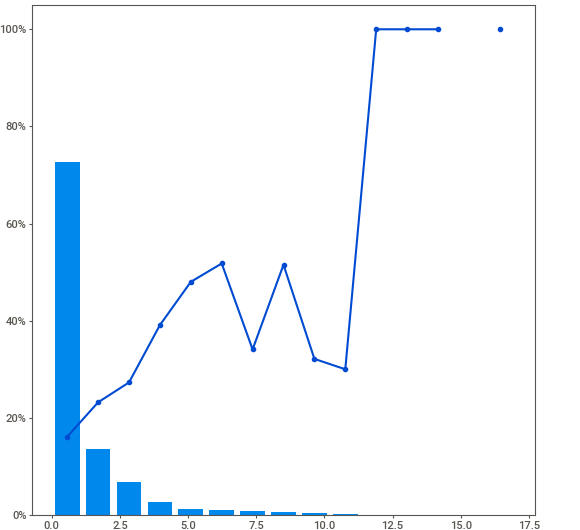
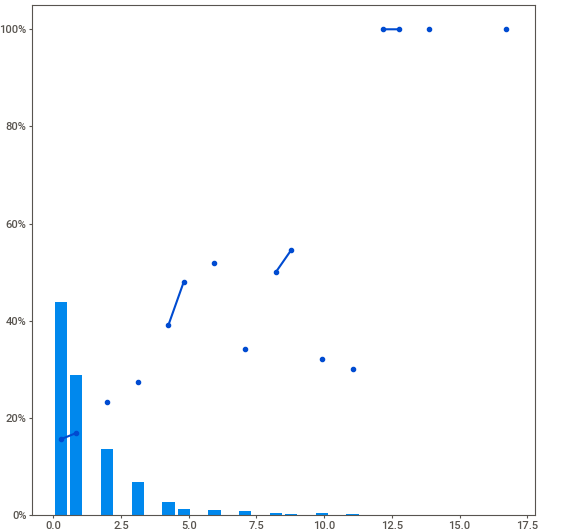
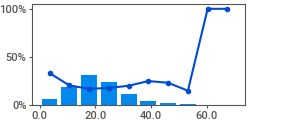
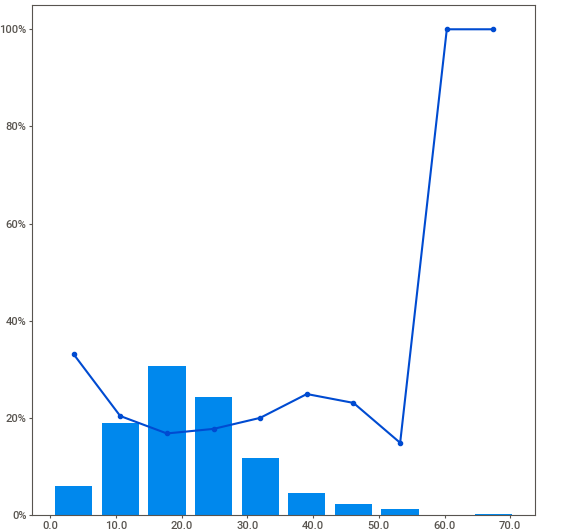
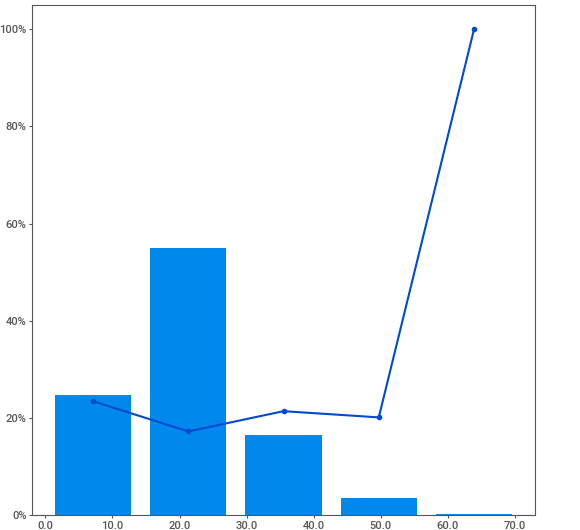
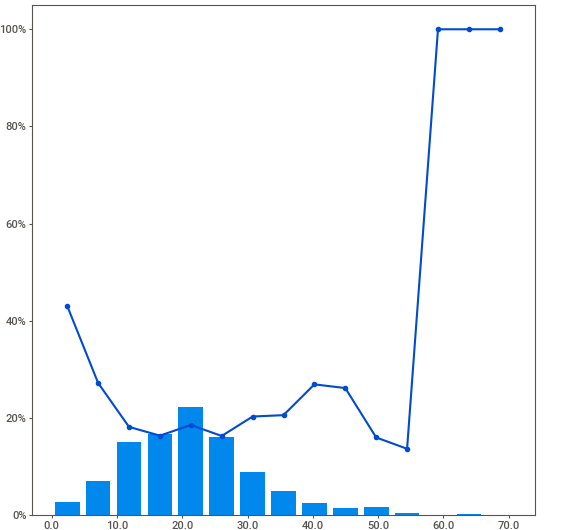
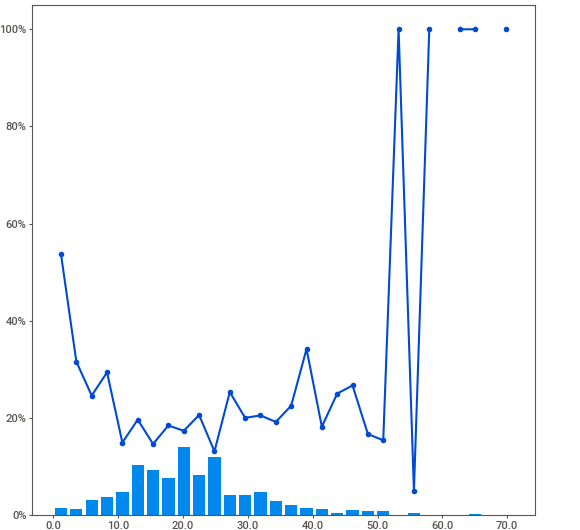
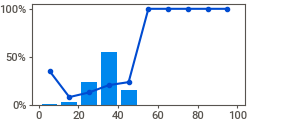
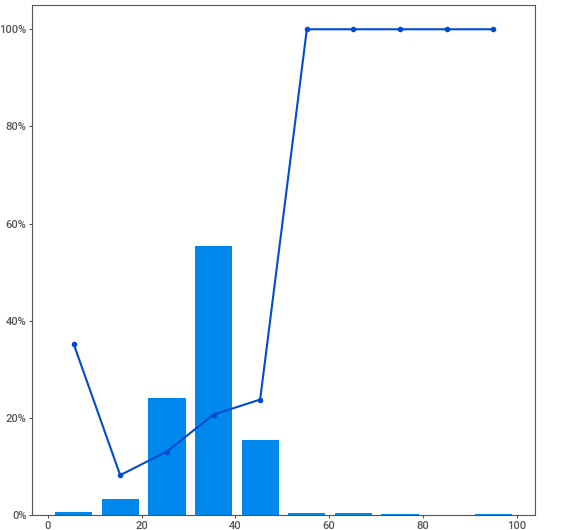
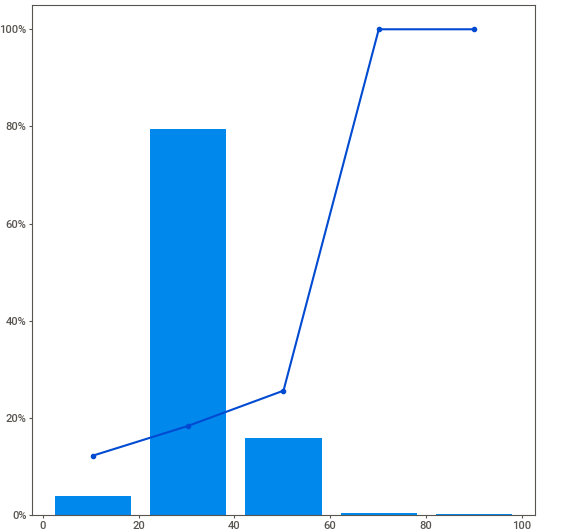
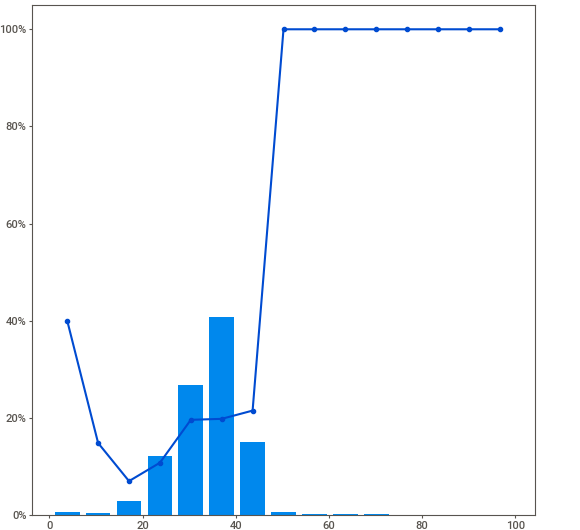
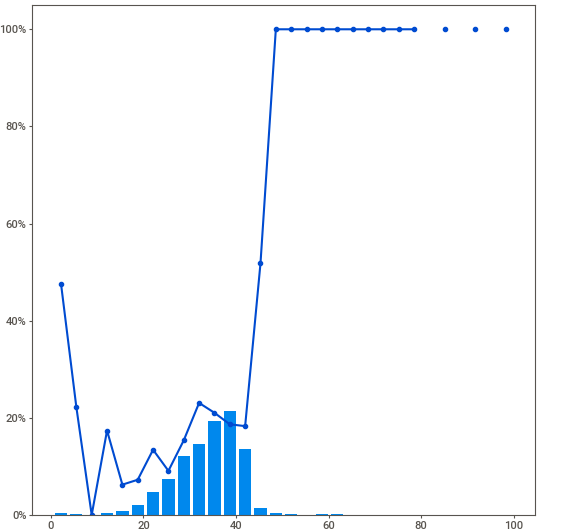
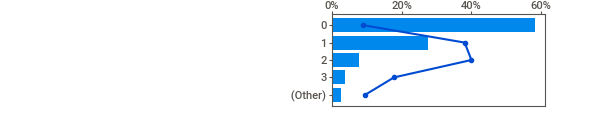
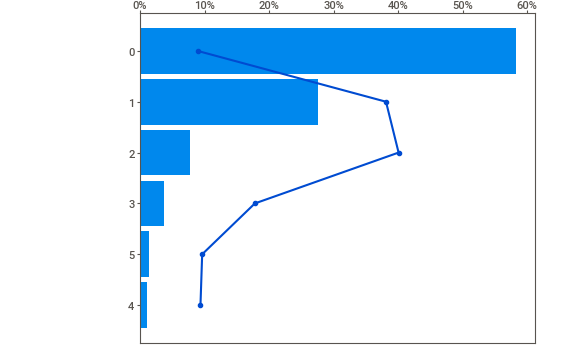
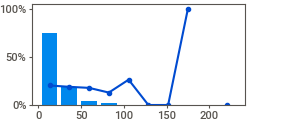
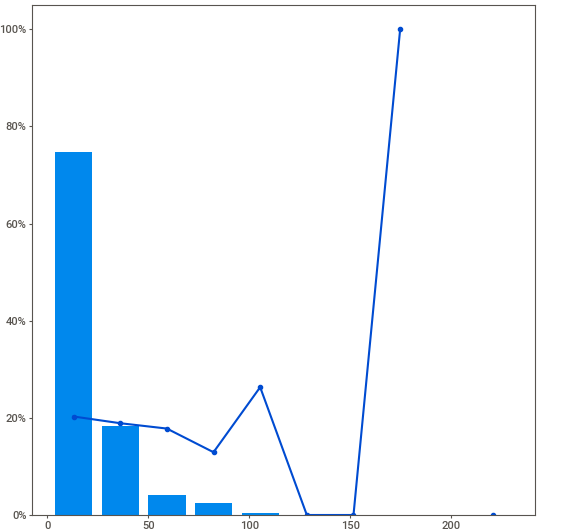
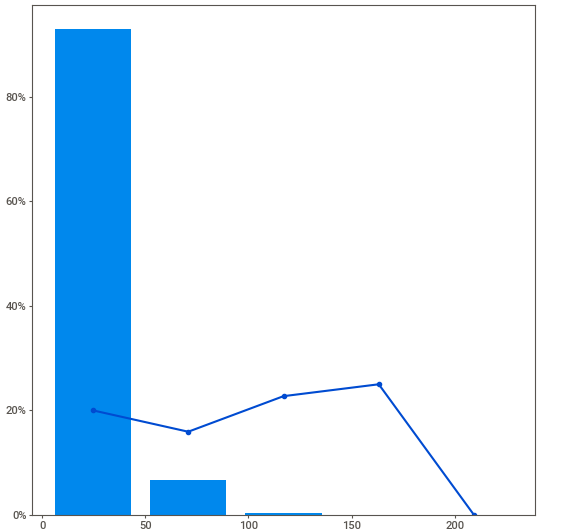
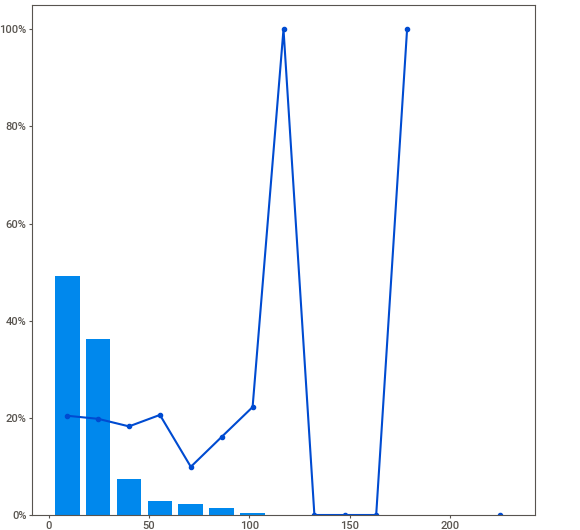
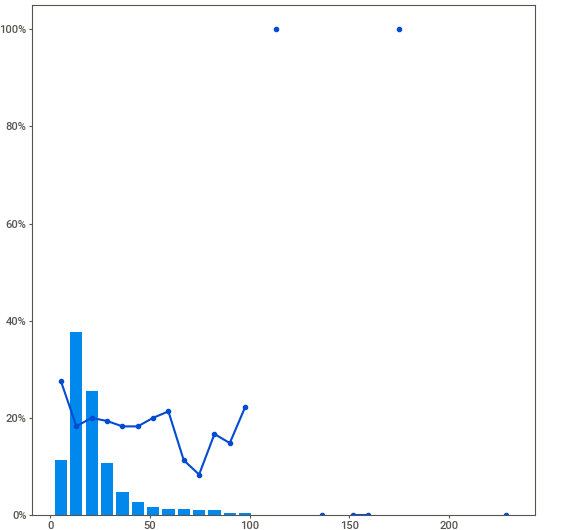
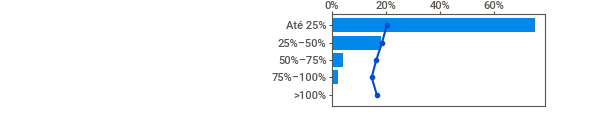
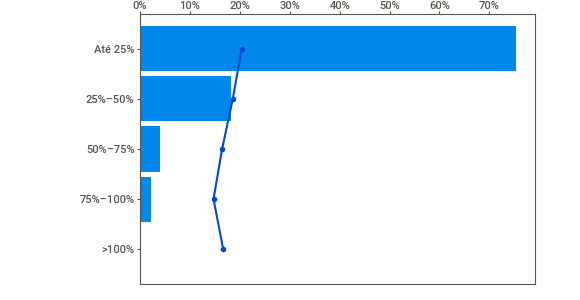
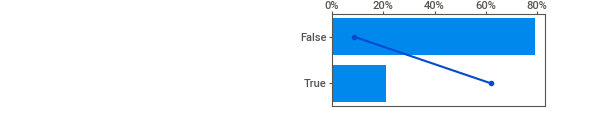
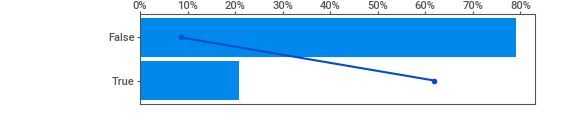
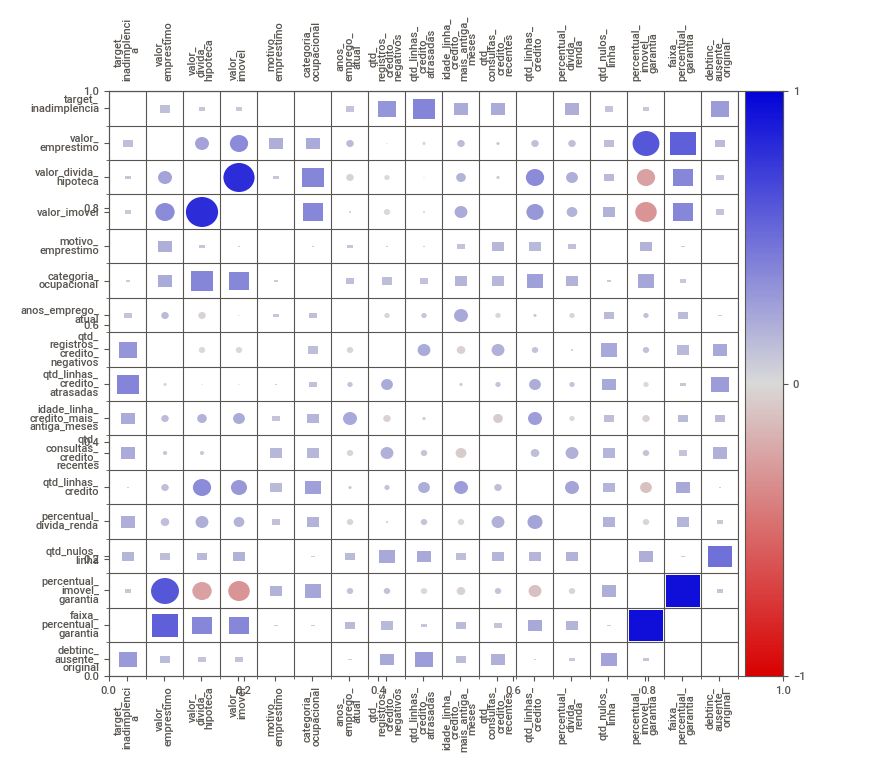
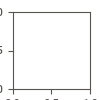

In [ ]:
# Exibe o relatório completo no notebook.
from IPython.display import HTML, display
from pathlib import Path
import html

conteudo_relatorio = Path("relatorio_hmeq_sweetviz.html").read_text(encoding="utf-8")
display(HTML(
    '<iframe title="Relatório_Sweetviz HMEQ" width="100%" height="560" '
    'style="border:1px solid #ddd" srcdoc="'
    + html.escape(conteudo_relatorio, quote=True)
    + '"></iframe>'
))

In [ ]:
# Evidências para comparar o relatório automático com a análise manual.
r_hipoteca_imovel = df_tratado["valor_divida_hipoteca"].corr(df_tratado["valor_imovel"])
print(f"Pearson entre dívida hipotecária e valor do imóvel: {r_hipoteca_imovel:.4f}")

percentuais_zero = (
    df_tratado[["qtd_linhas_credito_atrasadas", "qtd_registros_credito_negativos"]]
    .eq(0).mean().mul(100)
)
display(percentuais_zero.rename("Percentual de zeros").round(2).to_frame())

risco_por_ausencia = (
    df_relatorio.groupby("debtinc_ausente_original")["target_inadimplencia"]
    .agg(solicitacoes="size", inadimplentes="sum", taxa="mean")
)
risco_por_ausencia["taxa_percentual"] = risco_por_ausencia["taxa"] * 100
display(risco_por_ausencia.drop(columns="taxa").round(2))

# Quantifica os zeros resultantes da imputação, mantendo a origem dos dados.
origem_zeros = pd.DataFrame({
    "Zeros originalmente informados": [
        df_original["DELINQ"].reindex(df_tratado.index).eq(0).sum(),
        df_original["DEROG"].reindex(df_tratado.index).eq(0).sum()
    ],
    "Ausentes preenchidos com zero": [
        df_original["DELINQ"].reindex(df_tratado.index).isna().sum(),
        df_original["DEROG"].reindex(df_tratado.index).isna().sum()
    ]
}, index=["DELINQ", "DEROG"])
display(origem_zeros)

Pearson entre dívida hipotecária e valor do imóvel: 0.7928


,Percentual de zeros
qtd_linhas_credito_atrasadas,79.18
qtd_registros_credito_negativos,87.43


,solicitacoes,inadimplentes,taxa_percentual
debtinc_ausente_original,,,
False,4564,394,8.63
True,1204,745,61.88


,Zeros originalmente informados,Ausentes preenchidos com zero
DELINQ,4178,389
DEROG,4526,517


Aplicamos o Sweetviz à base tratada, com 5.768 registro, identificando BAD como variável alvo. Incluímos também um indicador que registra quais solicitações tinham DEBTINC originalmente ausente, preservando essa informação após a imputação.

A comparação com a análise manual confirmou o desbalanceamento do alvo, com 80,25% de adimplentes e 19,75 % de inadimplentes, e a associação da inadimplência com atrasos e registros negativos de crédito. Também confirmou que a base tratada não apresenta valores ausentes. Entretanto, essa completude resulta das imputações e não significa que todas as informações sejam originalmente conhecidas.

O relatório e as verificações complementares ampliaram a análise em três aspectos:

Relação entre variáveis explicativas: a dívida hipotecária e o valor do imóvel apresentaram correlação de Pearson de 0,793. Essa associação não era o foco da comparação individual das variáveis com BAD. Ela sugere informação compartilhada entre as duas medidas, sem justificar automaticamente a exclusão de uma delas.
Concentração de zeros: 79,18% dos registros apresentam zero em linhas de crédito atrasadas e 87,43% em registros negativos. Contudo, 389 valores de atraso e 517 de registros negativos foram preenchidos com zero pela mediana. Portanto, esses percentuais não podem ser interpretados como se todos fossem respostas originalmente informadas.
Importância da ausência original: entre os 1.204 registros cujo DEBTINC estava ausente, 745 eram inadimplentes, correspondendo a 61,88%. Entre os 4.564 com DEBTINC informado, 394 eram inadimplentes, correspondendo a 8,63%. Essa diferença mostra que o padrão de ausência também merece investigação, sem provar seu mecanismo ou sua causa.
Assim, a análise automatizada ajudou a evidenciar a associação entre dívida hipotecária e valor do imóvel. Sua comparação com os registros originais também permitiu interpretar melhor a concentração de zeros e o sinal presente na ausência de DEBTINC. O relatório não substitui a justificativa dos tratamentos nem permite concluir causalidade.

OBS: O Sweetviz utiliza Pearson entre variáveis numéricas, coeficiente de incerteza entre categóricas e razão de correlação nas associações entre categóricas e numéricas. Não devemos chamar todas essas medidas de Pearson ou Spearman; os cálculos específicos desses dois coeficientes estão na Tarefa 11.

**Tarefa 16:** Escrevam, em texto, 3 insights no formato Achado / Evidência /Ação Recomendada, como se fossem apresentar para a diretoria de risco do banco (sem jargão técnico na parte do “achado” e da “ação”).

Para o primeiro insight, a comparação abaixo considera apenas os valores de DELINQ originalmente informados. Isso evita tratar um atraso desconhecido, preenchido com zero, como ausência comprovada de atraso. Os demais insights utilizam os resultados das tarefas 14 e 15.

In [ ]:
atraso_original = df_original["DELINQ"].reindex(df_tratado.index)
base_atrasos = df_tratado.loc[atraso_original.notna()].copy()
base_atrasos["possui_atraso"] = atraso_original.loc[base_atrasos.index] > 0
resumo_atrasos = (
    base_atrasos.groupby("possui_atraso")["target_inadimplencia"]
    .agg(solicitacoes="size", inadimplentes="sum", taxa="mean")
)
resumo_atrasos["taxa_percentual"] = resumo_atrasos["taxa"] * 100
display(resumo_atrasos.drop(columns="taxa").round(2))

,solicitacoes,inadimplentes,taxa_percentual
possui_atraso,,,
False,4178,582,13.93
True,1201,534,44.46


### Insight 1 - Atrasos registrados acompanham maior inadimplência

**Achado :** Solicitações de clientes com linhas de crédito em atraso apresentam uma proporção maior de inadimplência.

**Evidência:** Considerando apenas os registros com informação original de atrasos, a inadimplência foi de 44,46% entre os clientes com algum atraso - 534 de 1.201 - contra 13,93% entre aqueles sem atraso - 582 de 4.178. A quantidade de linhas atrasadas também apresentou a maior correlação com BAD entre as variáveis numéricas analisadas.

**Ação recomendada:** Priorizar a conferência do histórico de pagamentos nas propostas com atrasos registrados, combinando essa informação com renda e demais condições do cliente.

### Insight 2 - Comprometimento elevado de renda merece atenção

**Achado:** A faixa de maior comprometimento de renda concentra uma proporção elevada de inadimplência.

**Evidência:** Na base tratada, 143 das 247 solicitações com DEBTINC acima de 43% eram inadimplentes, correspondendo a 57,89%. Nas outras faixas, as taxas ficaram entre 13,78% e 19,86%. Os valores incluem imputações e os cortes são exploratórios.

**Ação recomendada:** Conferir a capacidade de pagamento e testar, em outros dados, a utilidade dessas faixas para orientar a revisão das propostas, antes de estabelecer limites de concessão.

### Insight 3 - Informações ausentes exigem investigação

**Achado:** A falta de informação sobre dívida e renda está associada a um perfil diferente de inadimplência.

**Evidência:** Entre os registros mantidos, a inadimplência foi de 61,88% quando DEBTINC estava originalmente ausente, contra 8,63% quando estava informado. O preenchimento posterior desses valores não elimina essa diferença nem garante que as estimativas correspondam aos valores reais.

**Ação recomendada:** Investigar por que essa informação não foi registrada, em que momento ela é coletada e como melhorar sua obtenção. Manter a identificação dos valores estimados e evitar recusas automáticas fundamentadas apenas na ausência da informação.